In [1]:
import sys
from pathlib import Path

PROJECT_ROOT = Path.cwd().parent
SRC_PATH = PROJECT_ROOT / "src"

if str(SRC_PATH) not in sys.path:
    sys.path.append(str(SRC_PATH))

print("Project root:", PROJECT_ROOT)
print("Source path:", SRC_PATH)

Project root: C:\Users\prafu\Desktop\Wireless Signal Classification
Source path: C:\Users\prafu\Desktop\Wireless Signal Classification\src


In [2]:
import numpy as np
import matplotlib.pyplot as plt

from signal_generation.modulation import (
    generate_bits,
    bits_to_integers,
    bpsk_modulate,
    qpsk_modulate,
    psk8_modulate,
    qam16_modulate,
    modulate
)

from signal_generation.pulse_shaping import (
    rrc_filter,
    pulse_shape
)

from channel.awgn import add_awgn

print("All imports successful.")

All imports successful.


In [3]:
rng = np.random.default_rng(42)

bits = generate_bits(20, rng)

print("Generated bits:")
print(bits)

print("\nNumber of bits:", len(bits))
print("Unique values:", np.unique(bits))

Generated bits:
[0 1 1 0 0 1 0 1 0 0 1 1 1 1 1 1 1 0 1 0]

Number of bits: 20
Unique values: [0 1]


In [4]:
bits = np.array([
    0, 0,
    0, 1,
    1, 0,
    1, 1
])

symbol_indices = bits_to_integers(bits, 2)

print("Bits:")
print(bits)

print("\nSymbol indices:")
print(symbol_indices)

Bits:
[0 0 0 1 1 0 1 1]

Symbol indices:
[0 1 2 3]


In [5]:
bits = np.array([0, 1, 0, 1, 1, 0])

symbols = bpsk_modulate(bits)

print("Bits:")
print(bits)

print("\nBPSK symbols:")
print(symbols)

Bits:
[0 1 0 1 1 0]

BPSK symbols:
[ 1.+0.j -1.+0.j  1.+0.j -1.+0.j -1.+0.j  1.+0.j]


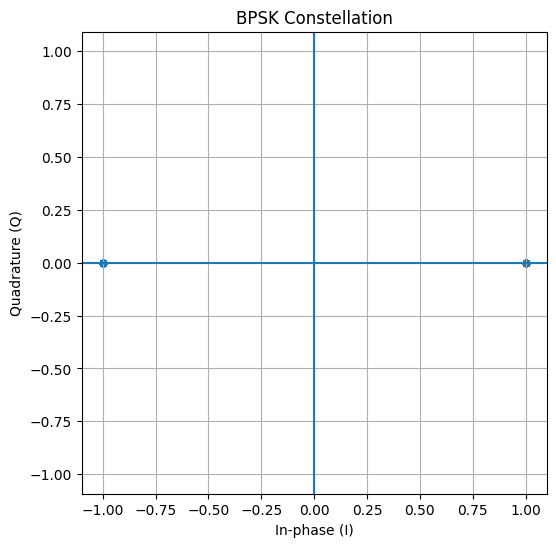

In [6]:
rng = np.random.default_rng(42)

num_symbols = 1000

bits = generate_bits(num_symbols, rng)
symbols = bpsk_modulate(bits)

plt.figure(figsize=(6, 6))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=20,
    alpha=0.5
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("BPSK Constellation")

plt.grid(True)
plt.axis("equal")
plt.show()

In [7]:
bits = np.array([
    0, 0,
    0, 1,
    1, 0,
    1, 1
])

symbols = qpsk_modulate(bits)

print("Bits:")
print(bits.reshape(-1, 2))

print("\nQPSK symbols:")
print(symbols)

print("\nMagnitude:")
print(np.abs(symbols))

print("\nPhase in degrees:")
print(np.angle(symbols, deg=True))

Bits:
[[0 0]
 [0 1]
 [1 0]
 [1 1]]

QPSK symbols:
[ 0.70710678+0.70710678j -0.70710678+0.70710678j  0.70710678-0.70710678j
 -0.70710678-0.70710678j]

Magnitude:
[1. 1. 1. 1.]

Phase in degrees:
[  45.  135.  -45. -135.]


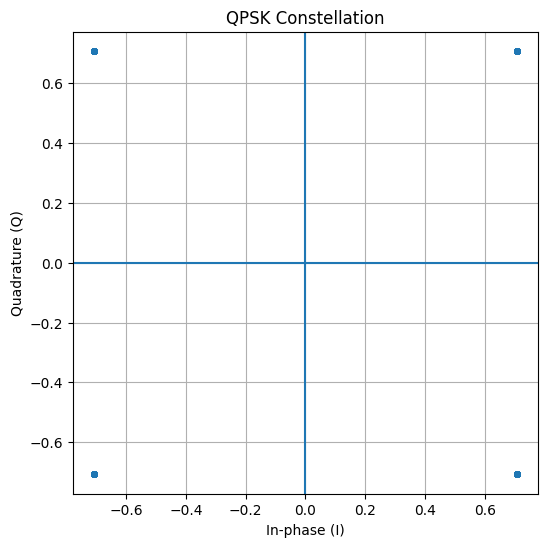

In [8]:
rng = np.random.default_rng(42)

num_symbols = 1000
bits = generate_bits(num_symbols * 2, rng)

symbols = qpsk_modulate(bits)

plt.figure(figsize=(6, 6))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=15,
    alpha=0.5
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("QPSK Constellation")

plt.grid(True)
plt.axis("equal")
plt.show()

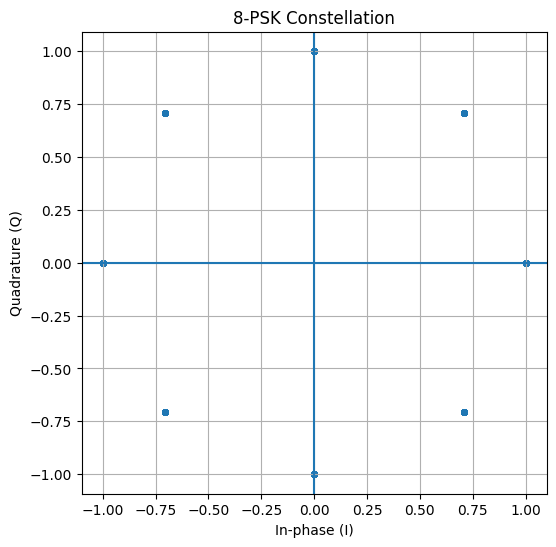

In [9]:
rng = np.random.default_rng(42)

num_symbols = 1000

bits = generate_bits(num_symbols * 3, rng)

symbols = psk8_modulate(bits)

plt.figure(figsize=(6, 6))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=15,
    alpha=0.5
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("8-PSK Constellation")

plt.grid(True)
plt.axis("equal")
plt.show()

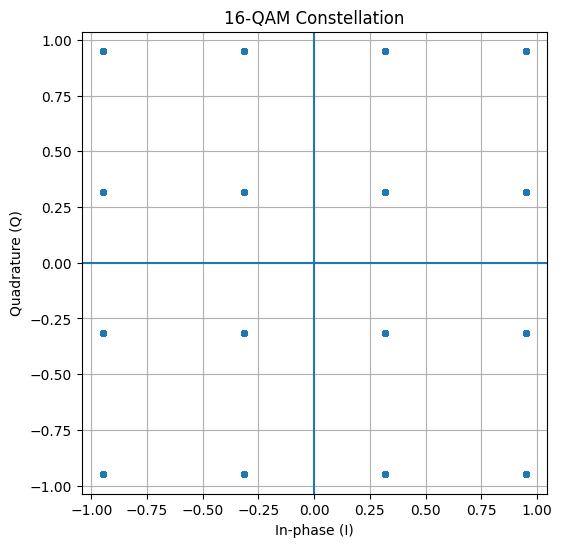

In [10]:
rng = np.random.default_rng(42)

num_symbols = 2000

bits = generate_bits(num_symbols * 4, rng)

symbols = qam16_modulate(bits)

plt.figure(figsize=(6, 6))

plt.scatter(
    symbols.real,
    symbols.imag,
    s=15,
    alpha=0.5
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("In-phase (I)")
plt.ylabel("Quadrature (Q)")
plt.title("16-QAM Constellation")

plt.grid(True)
plt.axis("equal")
plt.show()

In [11]:
rng = np.random.default_rng(42)

modulations = [
    "BPSK",
    "QPSK",
    "8PSK",
    "16QAM"
]

bits_per_symbol = {
    "BPSK": 1,
    "QPSK": 2,
    "8PSK": 3,
    "16QAM": 4
}

for modulation in modulations:

    num_symbols = 1000

    num_bits = (
        num_symbols *
        bits_per_symbol[modulation]
    )

    bits = generate_bits(num_bits, rng)

    symbols = modulate(
        bits,
        modulation
    )

    print(
        f"{modulation}: "
        f"{len(bits)} bits → "
        f"{len(symbols)} symbols"
    )

BPSK: 1000 bits → 1000 symbols
QPSK: 2000 bits → 1000 symbols
8PSK: 3000 bits → 1000 symbols
16QAM: 4000 bits → 1000 symbols


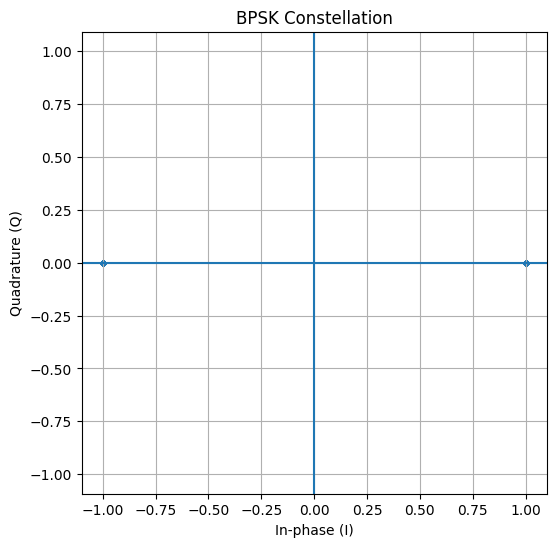

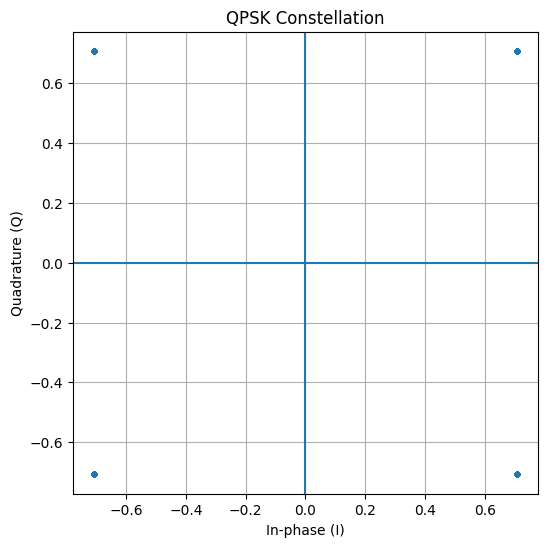

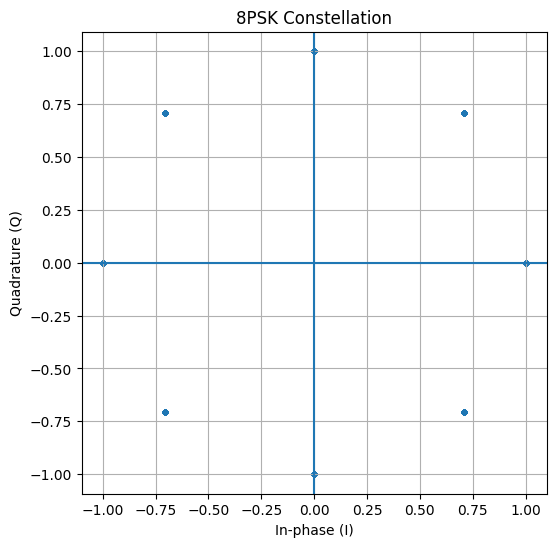

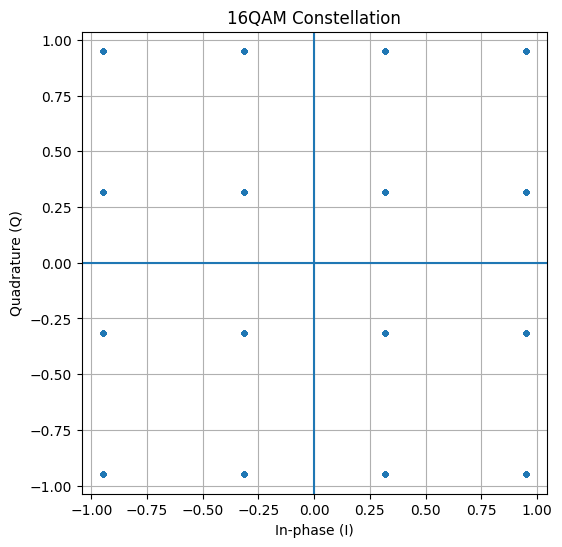

In [12]:
rng = np.random.default_rng(42)

modulations = [
    "BPSK",
    "QPSK",
    "8PSK",
    "16QAM"
]

bits_per_symbol = {
    "BPSK": 1,
    "QPSK": 2,
    "8PSK": 3,
    "16QAM": 4
}

for modulation in modulations:

    num_symbols = 1000

    num_bits = (
        num_symbols *
        bits_per_symbol[modulation]
    )

    bits = generate_bits(
        num_bits,
        rng
    )

    symbols = modulate(
        bits,
        modulation
    )

    plt.figure(figsize=(6, 6))

    plt.scatter(
        symbols.real,
        symbols.imag,
        s=10,
        alpha=0.5
    )

    plt.axhline(0)
    plt.axvline(0)

    plt.xlabel("In-phase (I)")
    plt.ylabel("Quadrature (Q)")

    plt.title(
        f"{modulation} Constellation"
    )

    plt.grid(True)
    plt.axis("equal")

    plt.show()

In [13]:
rng = np.random.default_rng(42)

for modulation in modulations:

    num_symbols = 10000

    num_bits = (
        num_symbols *
        bits_per_symbol[modulation]
    )

    bits = generate_bits(
        num_bits,
        rng
    )

    symbols = modulate(
        bits,
        modulation
    )

    power = np.mean(
        np.abs(symbols) ** 2
    )

    print(
        f"{modulation}: "
        f"average power = {power:.4f}"
    )

BPSK: average power = 1.0000
QPSK: average power = 1.0000
8PSK: average power = 1.0000
16QAM: average power = 0.9914


In [14]:
beta = 0.35
span = 8
sps = 8

h = rrc_filter(
    beta=beta,
    span=span,
    sps=sps
)

print("Number of taps:", len(h))
print("Filter coefficients:")
print(h)

Number of taps: 65
Filter coefficients:
[ 0.00072242  0.00312321  0.00471011  0.00488551  0.00338484  0.0004048
 -0.0033766  -0.00690936 -0.00900055 -0.00862136 -0.00522457  0.00100736
  0.00905759  0.01716309  0.02310611  0.02467263  0.02019768  0.00908697
 -0.007805   -0.02804394 -0.04779472 -0.06231475 -0.06670162 -0.05677657
 -0.02994691  0.01411944  0.07315072  0.14234992  0.21491186  0.28291406
  0.33844465  0.37478154  0.38742174  0.37478154  0.33844465  0.28291406
  0.21491186  0.14234992  0.07315072  0.01411944 -0.02994691 -0.05677657
 -0.06670162 -0.06231475 -0.04779472 -0.02804394 -0.007805    0.00908697
  0.02019768  0.02467263  0.02310611  0.01716309  0.00905759  0.00100736
 -0.00522457 -0.00862136 -0.00900055 -0.00690936 -0.0033766   0.0004048
  0.00338484  0.00488551  0.00471011  0.00312321  0.00072242]


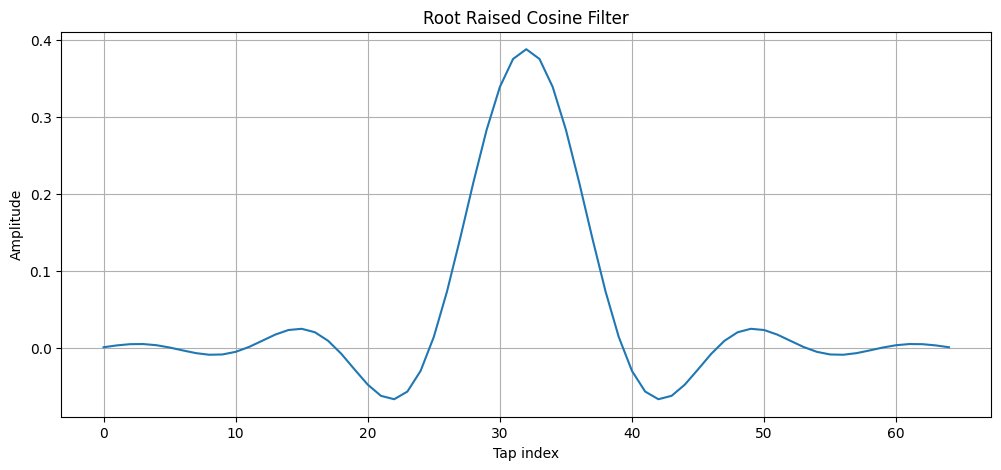

In [15]:
plt.figure(figsize=(12, 5))

plt.plot(h)

plt.xlabel("Tap index")
plt.ylabel("Amplitude")
plt.title("Root Raised Cosine Filter")

plt.grid(True)
plt.show()

In [16]:
energy = np.sum(h ** 2)

print("Filter energy:", energy)

Filter energy: 1.0


In [17]:
rng = np.random.default_rng(42)

modulation = "QPSK"

num_symbols = 200
sps = 8

bits = generate_bits(
    num_symbols * 2,
    rng
)

symbols = modulate(
    bits,
    modulation
)

print("Number of symbols:", len(symbols))
print("First 10 symbols:")
print(symbols[:10])

Number of symbols: 200
First 10 symbols:
[-0.70710678+0.70710678j  0.70710678-0.70710678j -0.70710678+0.70710678j
 -0.70710678+0.70710678j  0.70710678+0.70710678j -0.70710678-0.70710678j
 -0.70710678-0.70710678j -0.70710678-0.70710678j  0.70710678-0.70710678j
  0.70710678-0.70710678j]


In [18]:
waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=sps
)

print("Number of symbols:", len(symbols))
print("Number of waveform samples:", len(waveform))
print("Waveform shape:", waveform.shape)

Number of symbols: 200
Number of waveform samples: 1600
Waveform shape: (1600,)


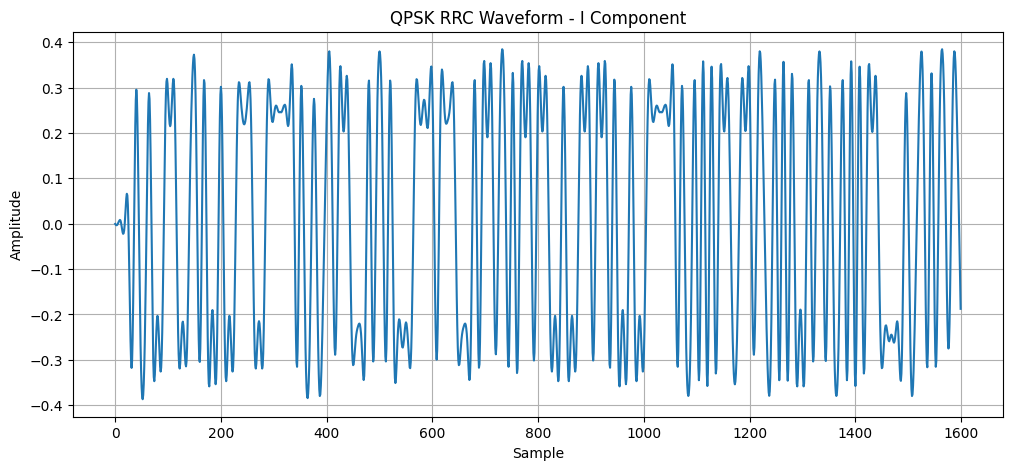

In [19]:
plt.figure(figsize=(12, 5))

plt.plot(
    waveform.real
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    "QPSK RRC Waveform - I Component"
)

plt.grid(True)
plt.show()

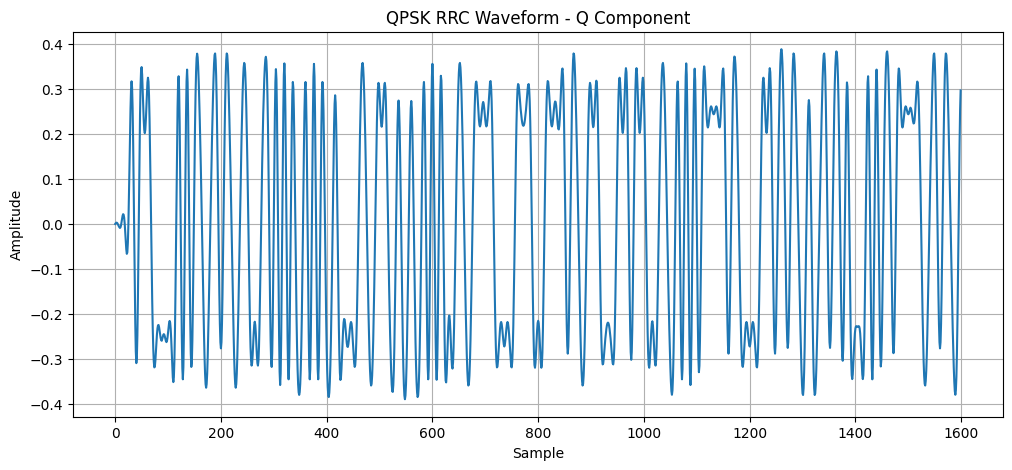

In [20]:
plt.figure(figsize=(12, 5))

plt.plot(
    waveform.imag
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    "QPSK RRC Waveform - Q Component"
)

plt.grid(True)
plt.show()

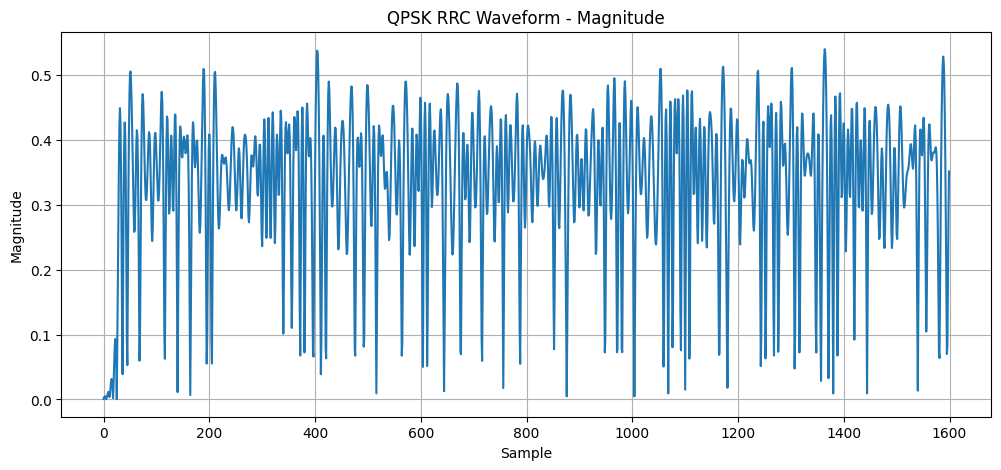

In [21]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.abs(waveform)
)

plt.xlabel("Sample")
plt.ylabel("Magnitude")

plt.title(
    "QPSK RRC Waveform - Magnitude"
)

plt.grid(True)
plt.show()

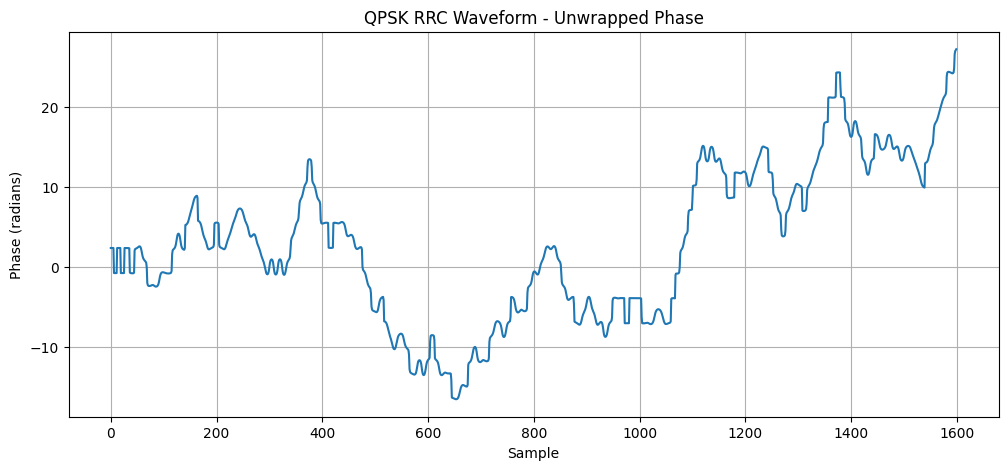

In [22]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.unwrap(np.angle(waveform))
)

plt.xlabel("Sample")
plt.ylabel("Phase (radians)")

plt.title(
    "QPSK RRC Waveform - Unwrapped Phase"
)

plt.grid(True)
plt.show()

In [23]:
delay = (8 * 8) // 2

symbol_samples = waveform[
    delay::sps
]

print("Original symbols:", len(symbols))
print("Extracted samples:", len(symbol_samples))

Original symbols: 200
Extracted samples: 196


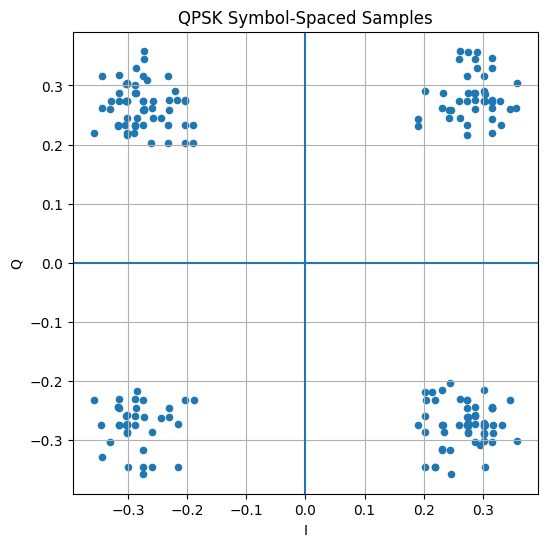

In [24]:
plt.figure(figsize=(6, 6))

plt.scatter(
    symbol_samples.real,
    symbol_samples.imag,
    s=20
)

plt.axhline(0)
plt.axvline(0)

plt.xlabel("I")
plt.ylabel("Q")

plt.title(
    "QPSK Symbol-Spaced Samples"
)

plt.grid(True)
plt.axis("equal")

plt.show()

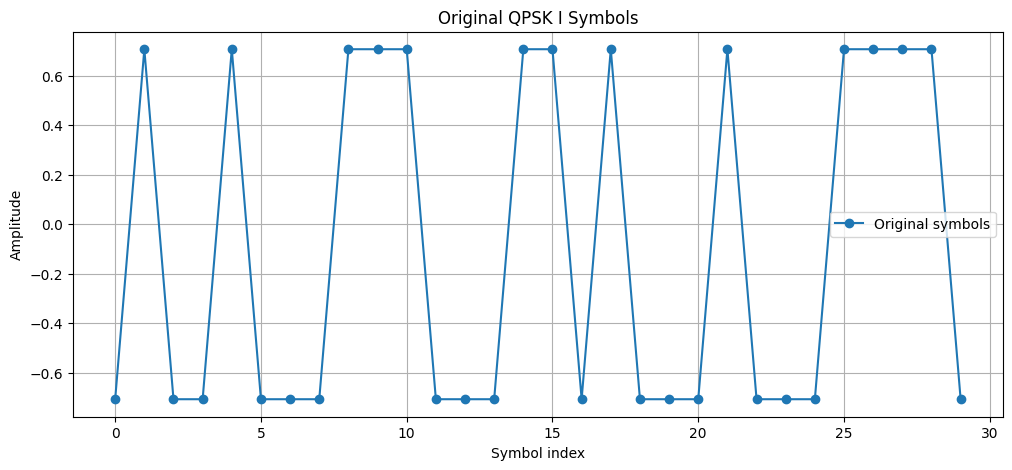

In [25]:
plt.figure(figsize=(12, 5))

plt.plot(
    symbols.real[:30],
    marker="o",
    label="Original symbols"
)

plt.xlabel("Symbol index")
plt.ylabel("Amplitude")

plt.title(
    "Original QPSK I Symbols"
)

plt.grid(True)
plt.legend()

plt.show()

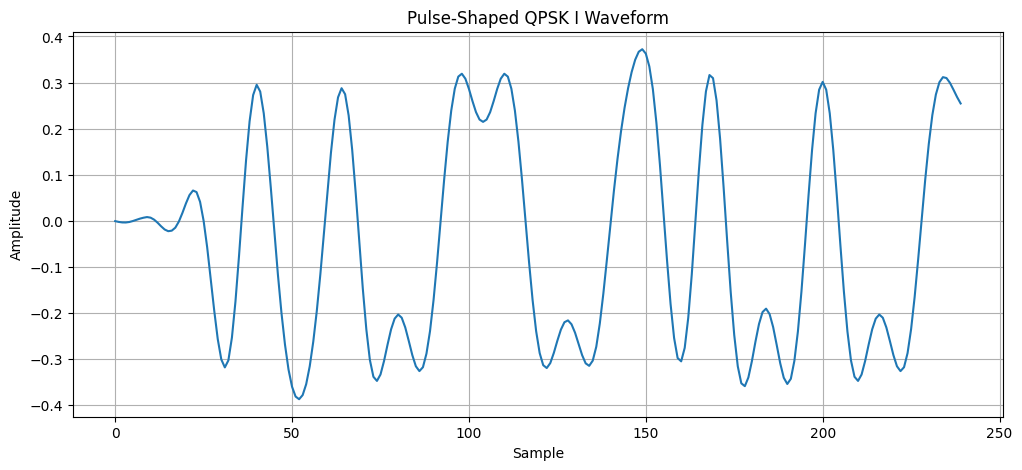

In [26]:
plt.figure(figsize=(12, 5))

plt.plot(
    waveform.real[:30 * sps]
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    "Pulse-Shaped QPSK I Waveform"
)

plt.grid(True)

plt.show()

In [27]:
print("========== SANITY CHECK ==========")

# 1. Bits
assert np.all(
    np.isin(bits, [0, 1])
)
print("✓ Bit generation")

# 2. Number of symbols
assert len(symbols) == num_symbols
print("✓ Symbol generation")

# 3. Waveform is complex
assert np.iscomplexobj(waveform)
print("✓ Complex waveform")

# 4. Correct waveform length
assert len(waveform) == len(symbols) * sps
print("✓ Waveform length")

# 5. RRC filter taps
assert len(h) == span * sps + 1
print("✓ RRC filter length")

# 6. Filter energy
assert np.isclose(
    np.sum(h ** 2),
    1.0,
    atol=1e-6
)
print("✓ RRC filter normalization")

print("\nALL BASIC TESTS PASSED ✓")

========== SANITY CHECK ==========
✓ Bit generation
✓ Symbol generation
✓ Complex waveform
✓ Waveform length
✓ RRC filter length
✓ RRC filter normalization

ALL BASIC TESTS PASSED ✓


In [28]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

num_symbols = 200

bits = rng.integers(0, 2, size=num_symbols * 2)

symbols = qpsk_modulate(bits)

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=8
)

print("Waveform shape:", waveform.shape)
print("Waveform dtype:", waveform.dtype)
print("Signal power:", np.mean(np.abs(waveform) ** 2))

Waveform shape: (1600,)
Waveform dtype: complex128
Signal power: 0.12283279089097089


In [29]:
noisy_waveform, noise = add_awgn(
    waveform,
    snr_db=10,
    rng=rng
)

print("Clean signal power:",
      np.mean(np.abs(waveform) ** 2)) 

print("Noise power:",
      np.mean(np.abs(noise) ** 2))

print("Noisy signal power:",
      np.mean(np.abs(noisy_waveform) ** 2))

Clean signal power: 0.12283279089097089
Noise power: 0.012451287440774237
Noisy signal power: 0.13500094605073398


In [30]:
signal_power = np.mean(np.abs(waveform) ** 2)
noise_power = np.mean(np.abs(noise) ** 2)

measured_snr_db = 10 * np.log10(signal_power / noise_power)

print("Target SNR:", 10, "dB")
print("Measured SNR:", measured_snr_db, "dB")

Target SNR: 10 dB
Measured SNR: 9.941000605666536 dB


In [31]:
snr_values = [-5, 0, 5, 10, 15, 20]

for snr_db in snr_values:

    noisy_signal, noise = add_awgn(
        waveform,
        snr_db=snr_db,
        rng=rng
    )

    signal_power = np.mean(np.abs(waveform) ** 2)
    noise_power = np.mean(np.abs(noise) ** 2)

    measured_snr = 10 * np.log10(signal_power / noise_power)

    print(
        f"Target: {snr_db:>3} dB | "
        f"Measured: {measured_snr:>6.2f} dB"
    )

Target:  -5 dB | Measured:  -5.10 dB
Target:   0 dB | Measured:  -0.08 dB
Target:   5 dB | Measured:   5.07 dB
Target:  10 dB | Measured:   9.98 dB
Target:  15 dB | Measured:  14.93 dB
Target:  20 dB | Measured:  20.00 dB


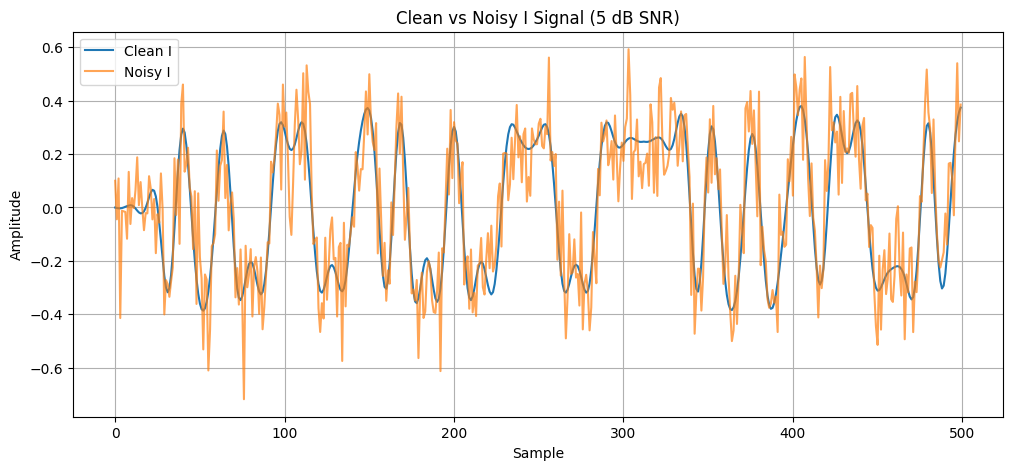

In [32]:
snr_db = 5

noisy_waveform, noise = add_awgn(
    waveform,
    snr_db=snr_db,
    rng=rng
)

num_plot_samples = 500

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:num_plot_samples]),
    label="Clean I"
)

plt.plot(
    np.real(noisy_waveform[:num_plot_samples]),
    label="Noisy I",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title(f"Clean vs Noisy I Signal ({snr_db} dB SNR)")
plt.legend()
plt.grid()
plt.show()

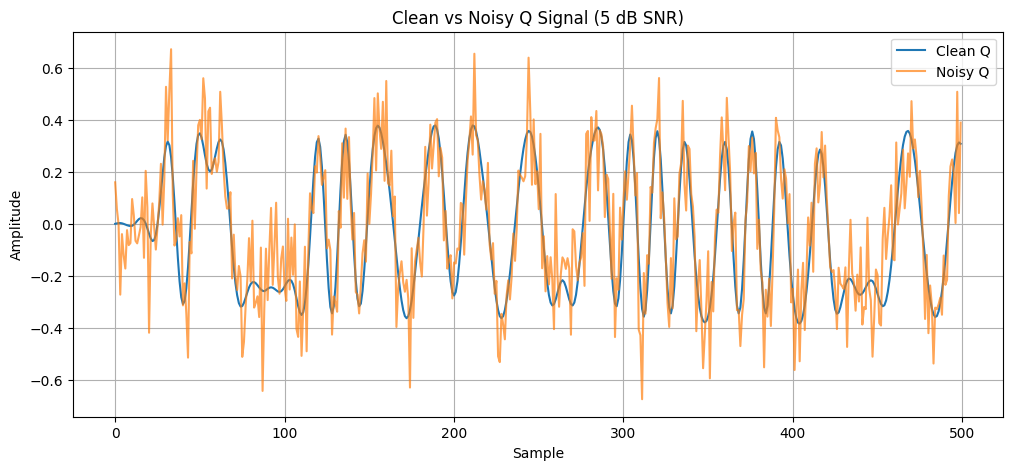

In [33]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.imag(waveform[:num_plot_samples]),
    label="Clean Q"
)

plt.plot(
    np.imag(noisy_waveform[:num_plot_samples]),
    label="Noisy Q",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title(f"Clean vs Noisy Q Signal ({snr_db} dB SNR)")
plt.legend()
plt.grid()
plt.show()

In [34]:
sps = 8
span = 8

group_delay = (span * sps) // 2

clean_symbols = waveform[group_delay::sps]

noisy_symbols = noisy_waveform[group_delay::sps]

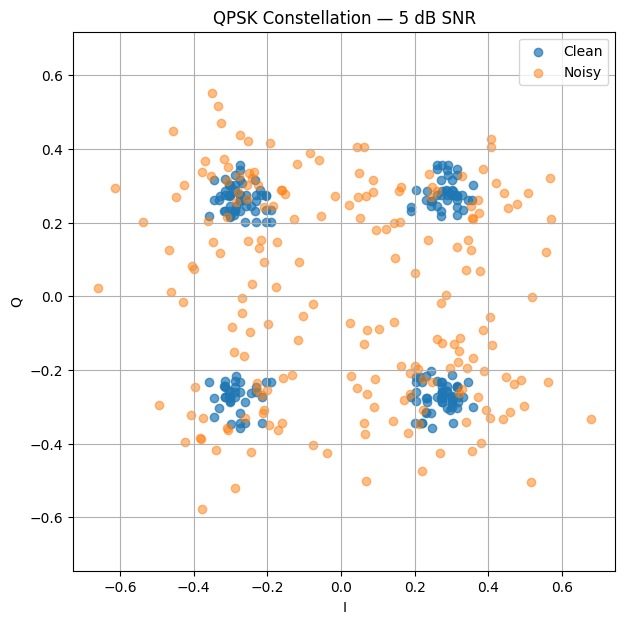

In [35]:
plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(clean_symbols),
    np.imag(clean_symbols),
    label="Clean",
    alpha=0.7
)

plt.scatter(
    np.real(noisy_symbols),
    np.imag(noisy_symbols),
    label="Noisy",
    alpha=0.5
)

plt.xlabel("I")
plt.ylabel("Q")
plt.title(f"QPSK Constellation — {snr_db} dB SNR")
plt.grid()
plt.axis("equal")
plt.legend()
plt.show()

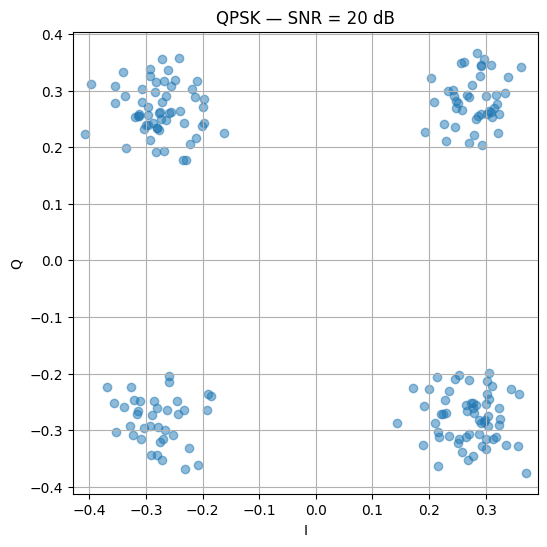

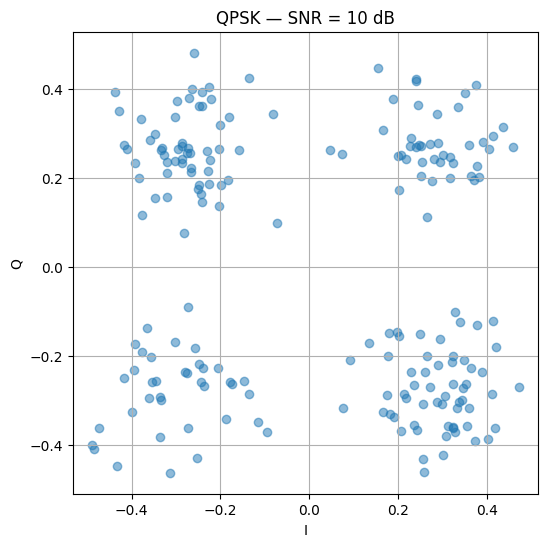

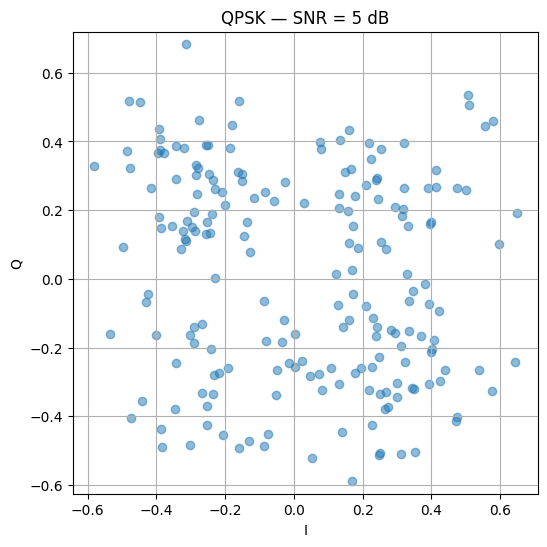

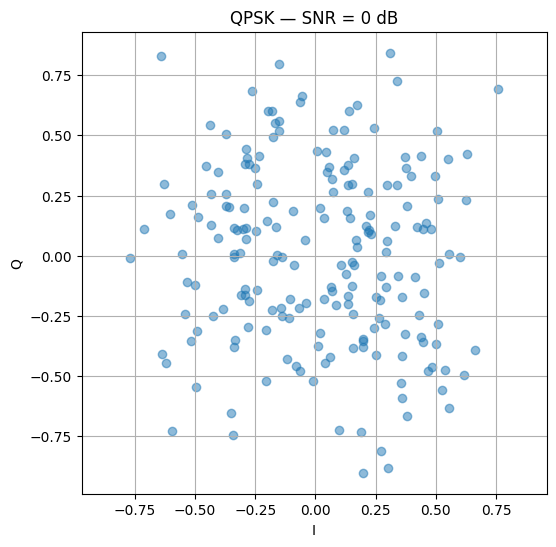

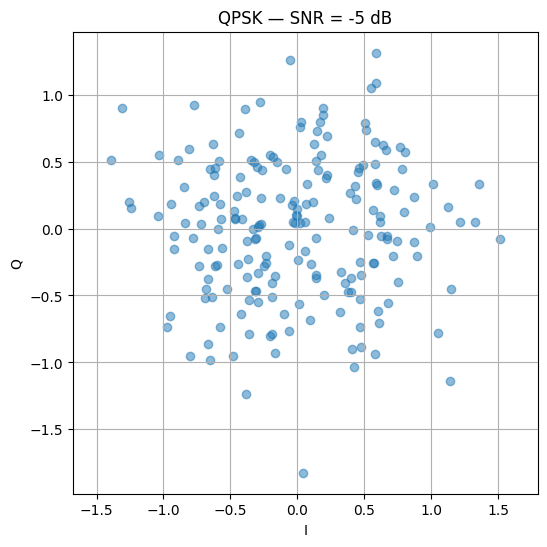

In [36]:
snr_values = [20, 10, 5, 0, -5]

for snr_db in snr_values:

    noisy_waveform, _ = add_awgn(
        waveform,
        snr_db=snr_db,
        rng=rng
    )

    noisy_symbols = noisy_waveform[group_delay::sps]

    plt.figure(figsize=(6, 6))

    plt.scatter(
        np.real(noisy_symbols),
        np.imag(noisy_symbols),
        alpha=0.5
    )

    plt.xlabel("I")
    plt.ylabel("Q")
    plt.title(f"QPSK — SNR = {snr_db} dB")
    plt.grid()
    plt.axis("equal")
    plt.show()

In [37]:
def measure_snr_db(signal, noise):
    signal_power = np.mean(np.abs(signal) ** 2)
    noise_power = np.mean(np.abs(noise) ** 2)

    return 10 * np.log10(signal_power / noise_power)

In [38]:
test_snr_values = [-5, 0, 5, 10, 15, 20]

for target_snr in test_snr_values:

    noisy_signal, noise = add_awgn(
        waveform,
        target_snr,
        rng=rng
    )

    measured_snr = measure_snr_db(
        waveform,
        noise
    )

    print(
        f"Target = {target_snr:>3} dB | "
        f"Measured = {measured_snr:>6.2f} dB"
    )

Target =  -5 dB | Measured =  -4.95 dB
Target =   0 dB | Measured =   0.07 dB
Target =   5 dB | Measured =   5.09 dB
Target =  10 dB | Measured =  10.02 dB
Target =  15 dB | Measured =  15.04 dB
Target =  20 dB | Measured =  19.91 dB


In [39]:
tolerance = 0.5

for target_snr in test_snr_values:

    _, noise = add_awgn(
        waveform,
        target_snr,
        rng=rng
    )

    measured_snr = measure_snr_db(
        waveform,
        noise
    )

    error = abs(measured_snr - target_snr)

    assert error < tolerance, (
        f"SNR test failed: "
        f"target={target_snr}, "
        f"measured={measured_snr:.2f}"
    )

print("All AWGN SNR tests passed.")

All AWGN SNR tests passed.


In [40]:
from channel.phase import apply_phase_offset, random_phase_offset

In [41]:
phase_rad = np.pi / 4

shifted_waveform = apply_phase_offset(
    waveform,
    phase_rad
)

print("Phase:", phase_rad)
print("Phase in degrees:", np.degrees(phase_rad))

Phase: 0.7853981633974483
Phase in degrees: 45.0


In [42]:
sample_index = 100

original = waveform[sample_index]
shifted = shifted_waveform[sample_index]

expected = original * np.exp(1j * phase_rad)

print("Original :", original)
print("Shifted  :", shifted)
print("Expected :", expected)

print(
    "Error:",
    abs(shifted - expected)
)

Original : (0.28633501348407997-0.24112621509460327j)
Shifted  : (0.3729714115409745+0.03196744791049445j)
Expected : (0.3729714115409745+0.03196744791049444j)
Error: 6.938893903907228e-18


In [43]:
original_magnitude = np.abs(waveform)
shifted_magnitude = np.abs(shifted_waveform)

print(
    "Maximum magnitude difference:",
    np.max(
        np.abs(
            original_magnitude - shifted_magnitude
        )
    )
)

Maximum magnitude difference: 2.220446049250313e-16


In [44]:
original_power = np.mean(
    np.abs(waveform) ** 2
)

shifted_power = np.mean(
    np.abs(shifted_waveform) ** 2
)

print("Original power:", original_power)
print("Shifted power :", shifted_power)

print(
    "Power difference:",
    abs(original_power - shifted_power)
)

Original power: 0.12283279089097089
Shifted power : 0.12283279089097093
Power difference: 4.163336342344337e-17


In [45]:
sps = 8
span = 8

group_delay = (span * sps) // 2

original_symbols = waveform[group_delay::sps]

shifted_symbols = shifted_waveform[group_delay::sps]

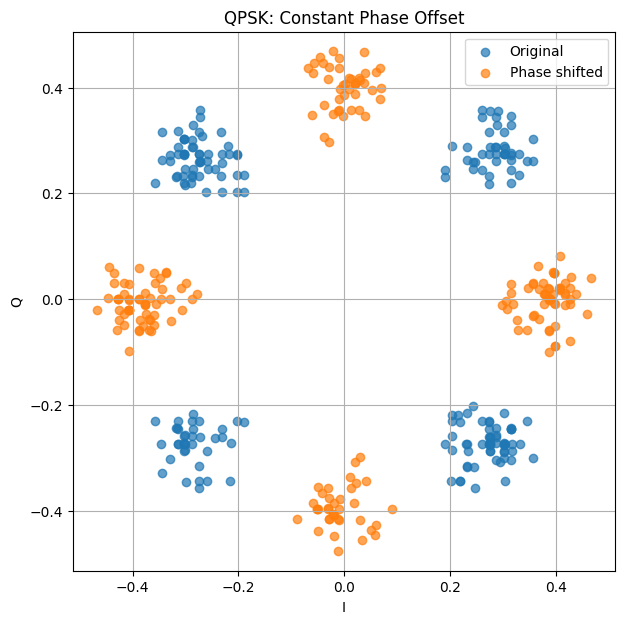

In [46]:
plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(original_symbols),
    np.imag(original_symbols),
    label="Original",
    alpha=0.7
)

plt.scatter(
    np.real(shifted_symbols),
    np.imag(shifted_symbols),
    label="Phase shifted",
    alpha=0.7
)

plt.xlabel("I")
plt.ylabel("Q")

plt.title("QPSK: Constant Phase Offset")

plt.axis("equal")
plt.grid()
plt.legend()

plt.show()

In [47]:
original_phase = np.angle(original_symbols)
shifted_phase = np.angle(shifted_symbols)

phase_difference = np.angle(
    np.exp(
        1j * (shifted_phase - original_phase)
    )
)

print(
    "Mean phase difference:",
    np.mean(phase_difference)
)

print(
    "Expected phase difference:",
    phase_rad
)

Mean phase difference: 0.7853981633974483
Expected phase difference: 0.7853981633974483


In [48]:
measured_phase_difference = np.angle(
    shifted_symbols / original_symbols
)

print(
    "Mean measured phase difference:",
    np.mean(measured_phase_difference)
)

print(
    "Expected:",
    phase_rad
)

Mean measured phase difference: 0.7853981633974483
Expected: 0.7853981633974483


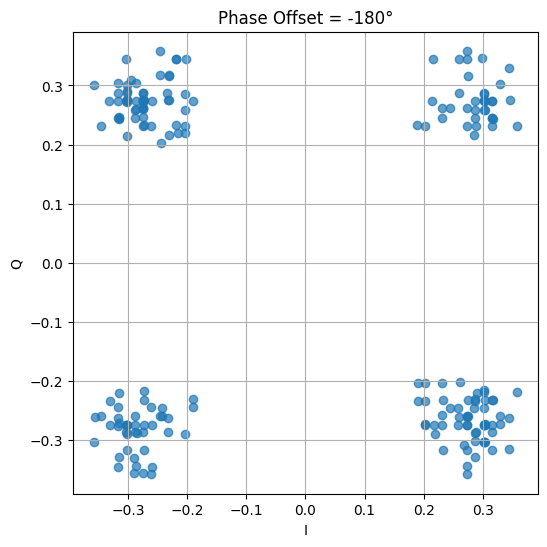

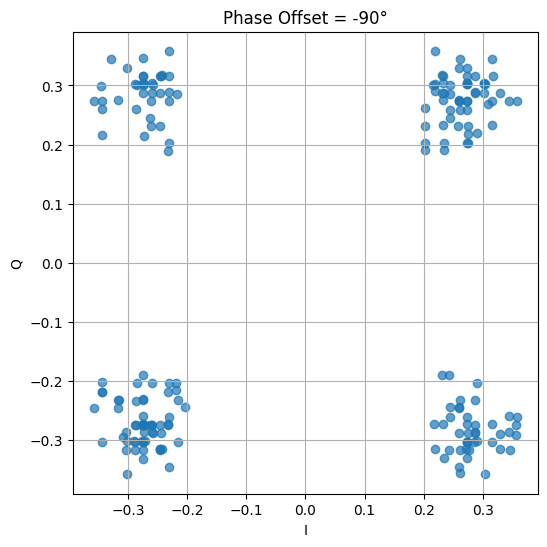

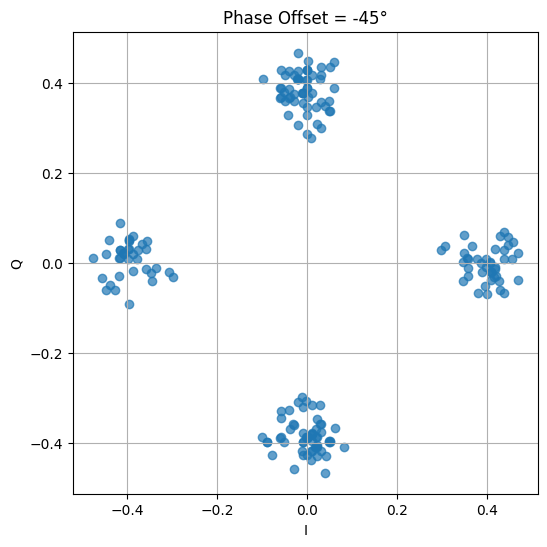

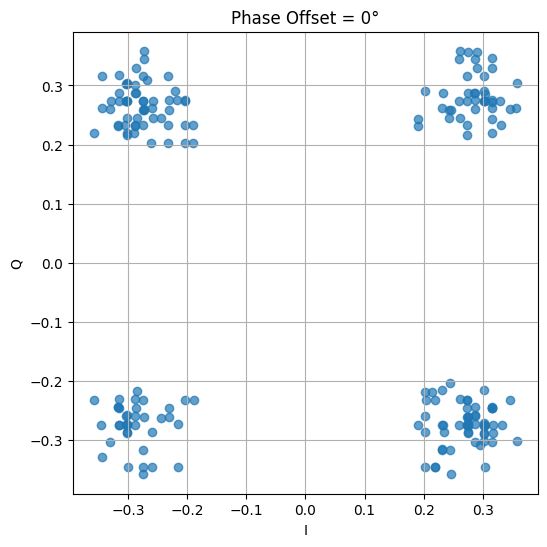

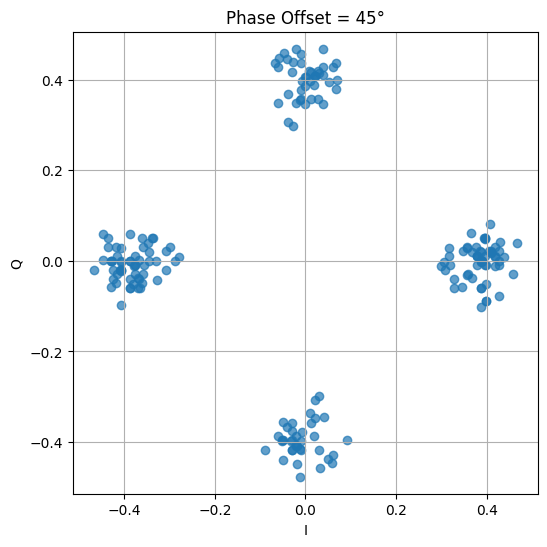

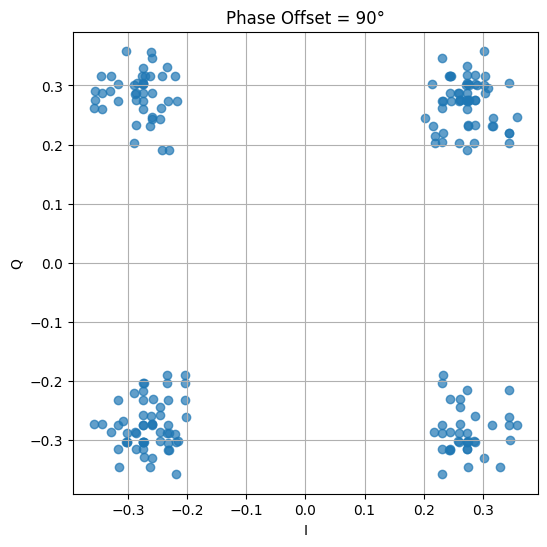

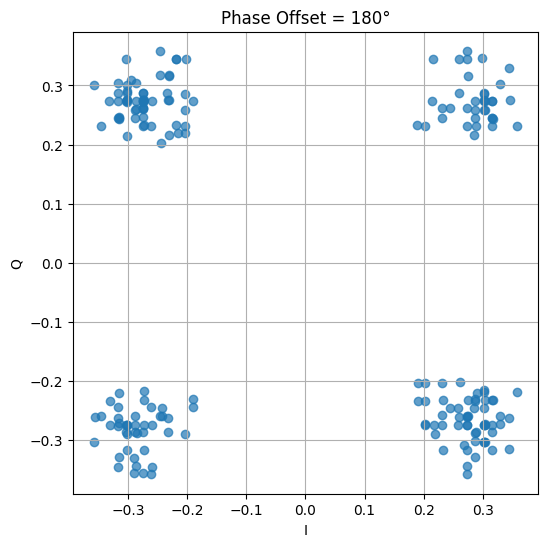

In [49]:
phase_values = [
    -np.pi,
    -np.pi / 2,
    -np.pi / 4,
    0,
    np.pi / 4,
    np.pi / 2,
    np.pi
]

for phase_rad in phase_values:

    shifted_waveform = apply_phase_offset(
        waveform,
        phase_rad
    )

    shifted_symbols = shifted_waveform[
        group_delay::sps
    ]

    plt.figure(figsize=(6, 6))

    plt.scatter(
        np.real(shifted_symbols),
        np.imag(shifted_symbols),
        alpha=0.7
    )

    plt.xlabel("I")
    plt.ylabel("Q")

    plt.title(
        f"Phase Offset = {np.degrees(phase_rad):.0f}°"
    )

    plt.axis("equal")
    plt.grid()

    plt.show()

In [50]:
rng = np.random.default_rng(42)

random_shifted, phase_used = random_phase_offset(
    waveform,
    rng=rng
)

print(
    "Random phase:",
    phase_used,
    "rad"
)

print(
    "Random phase:",
    np.degrees(phase_used),
    "degrees"
)

Random phase: 1.721316619099806 rad
Random phase: 98.62417748014678 degrees


In [51]:
assert -np.pi <= phase_used <= np.pi

print("Random phase range test passed.")

Random phase range test passed.


In [52]:
rng = np.random.default_rng(42)

phase_signal, phase_used = random_phase_offset(
    waveform,
    rng=rng
)

noisy_signal, noise = add_awgn(
    phase_signal,
    snr_db=10,
    rng=rng
)

print(
    "Phase:",
    np.degrees(phase_used),
    "degrees"
)

Phase: 98.62417748014678 degrees


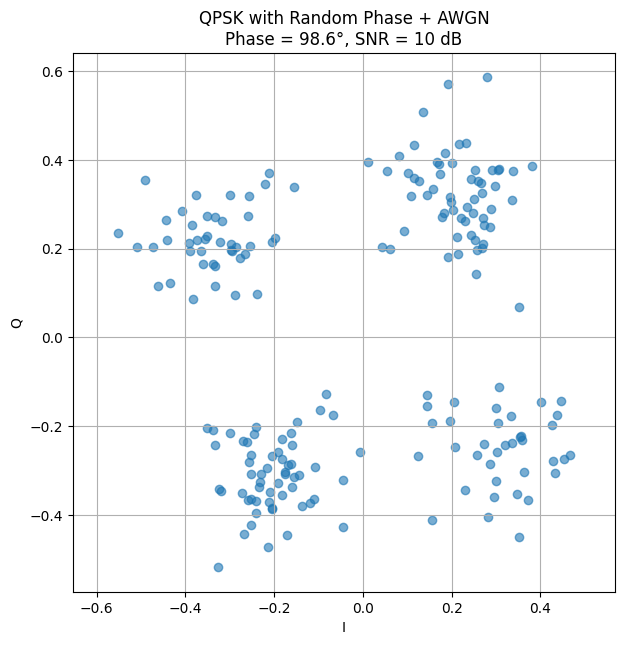

In [53]:
noisy_symbols = noisy_signal[
    group_delay::sps
]

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(noisy_symbols),
    np.imag(noisy_symbols),
    alpha=0.6
)

plt.xlabel("I")
plt.ylabel("Q")

plt.title(
    f"QPSK with Random Phase + AWGN\n"
    f"Phase = {np.degrees(phase_used):.1f}°, SNR = 10 dB"
)

plt.axis("equal")
plt.grid()

plt.show()

In [54]:
rng = np.random.default_rng(123)

test_phases = [
    -np.pi,
    -np.pi / 2,
    -np.pi / 4,
    0,
    np.pi / 4,
    np.pi / 2,
    np.pi
]

for phase_rad in test_phases:

    shifted = apply_phase_offset(
        waveform,
        phase_rad
    )

    # Magnitude must remain unchanged
    magnitude_error = np.max(
        np.abs(
            np.abs(shifted)
            - np.abs(waveform)
        )
    )

    assert magnitude_error < 1e-10

    # Power must remain unchanged
    original_power = np.mean(
        np.abs(waveform) ** 2
    )

    shifted_power = np.mean(
        np.abs(shifted) ** 2
    )

    assert abs(
        original_power - shifted_power
    ) < 1e-10

print("All constant-phase sanity checks passed.")

All constant-phase sanity checks passed.


In [55]:
sps = 8
symbol_rate_hz = 1e6

sample_rate_hz = sps * symbol_rate_hz

print("Sample rate:", sample_rate_hz / 1e6, "MHz")

Sample rate: 8.0 MHz


In [56]:
import numpy as np

rng = np.random.default_rng(42)

num_symbols = 200

bits = rng.integers(
    0,
    2,
    size=num_symbols * 2
)

symbols = qpsk_modulate(bits)

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=8
)

In [57]:
from channel.cfo import apply_cfo

In [58]:
cfo_hz = 100e3

cfo_signal = apply_cfo(
    waveform,
    cfo_hz=cfo_hz,
    sample_rate_hz=sample_rate_hz
)

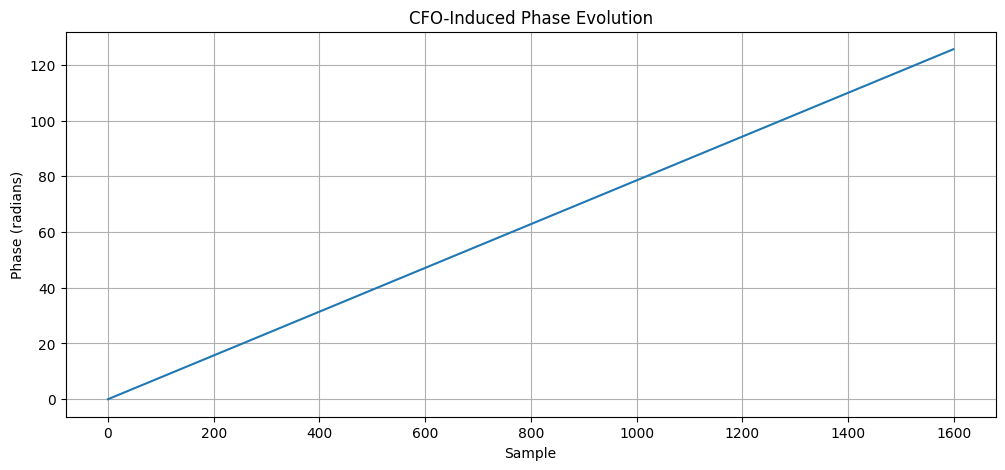

In [59]:
n = np.arange(len(waveform))

phase = 2 * np.pi * cfo_hz * n / sample_rate_hz

plt.figure(figsize=(12, 5))

plt.plot(phase)

plt.xlabel("Sample")
plt.ylabel("Phase (radians)")
plt.title("CFO-Induced Phase Evolution")

plt.grid()
plt.show()

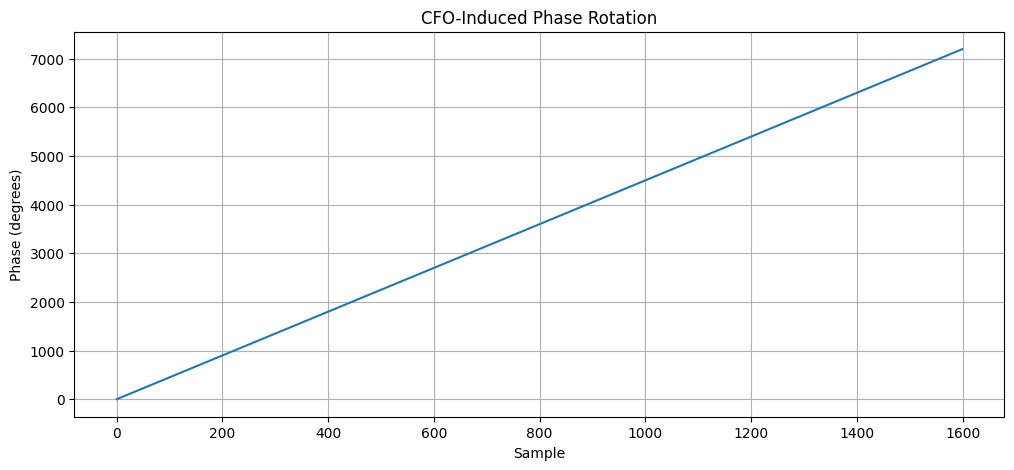

In [60]:
phase_degrees = np.degrees(phase)

plt.figure(figsize=(12, 5))

plt.plot(phase_degrees)

plt.xlabel("Sample")
plt.ylabel("Phase (degrees)")
plt.title("CFO-Induced Phase Rotation")

plt.grid()
plt.show()

In [61]:
expected_phase_increment = (
    2 * np.pi * cfo_hz / sample_rate_hz
)

print(
    "Expected phase increment:",
    expected_phase_increment,
    "rad/sample"
)

Expected phase increment: 0.07853981633974483 rad/sample


In [62]:
measured_phase_increment = np.mean(
    np.diff(phase)
)

print(
    "Expected:",
    expected_phase_increment
)

print(
    "Measured:",
    measured_phase_increment
)

Expected: 0.07853981633974483
Measured: 0.07853981633974481


In [63]:
assert np.isclose(
    measured_phase_increment,
    expected_phase_increment,
    atol=1e-12
)

print("CFO phase increment test passed.")

CFO phase increment test passed.


In [64]:
rotation = cfo_signal / waveform

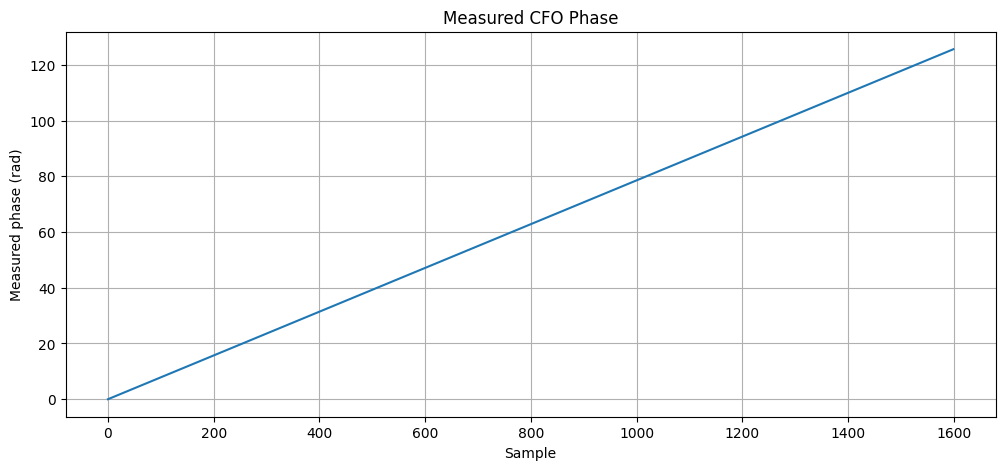

In [65]:
measured_phase = np.unwrap(
    np.angle(rotation)
)

plt.figure(figsize=(12, 5))

plt.plot(measured_phase)

plt.xlabel("Sample")
plt.ylabel("Measured phase (rad)")
plt.title("Measured CFO Phase")

plt.grid()
plt.show()

In [66]:
constant_phase_signal = apply_phase_offset(
    waveform,
    phase_rad=np.pi / 4
)

In [67]:
cfo_signal = apply_cfo(
    waveform,
    cfo_hz=100e3,
    sample_rate_hz=sample_rate_hz
)

In [68]:
constant_phase = np.unwrap(
    np.angle(
        constant_phase_signal / waveform
    )
)

In [69]:
cfo_phase = np.unwrap(
    np.angle(
        cfo_signal / waveform
    )
)

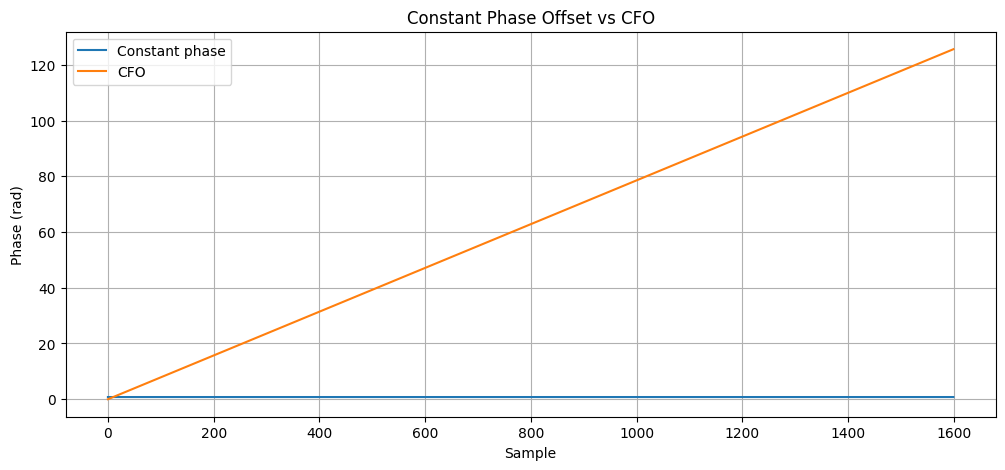

In [70]:
plt.figure(figsize=(12, 5))

plt.plot(
    constant_phase,
    label="Constant phase"
)

plt.plot(
    cfo_phase,
    label="CFO"
)

plt.xlabel("Sample")
plt.ylabel("Phase (rad)")

plt.title(
    "Constant Phase Offset vs CFO"
)

plt.grid()
plt.legend()

plt.show()

In [71]:
magnitude_error = np.max(
    np.abs(
        np.abs(cfo_signal)
        - np.abs(waveform)
    )
)

print(
    "Maximum magnitude error:",
    magnitude_error
)

Maximum magnitude error: 1.1102230246251565e-16


In [72]:
assert magnitude_error < 1e-10

print("CFO magnitude test passed.")

CFO magnitude test passed.


In [73]:
original_power = np.mean(
    np.abs(waveform) ** 2
)

cfo_power = np.mean(
    np.abs(cfo_signal) ** 2
)

print("Original power:", original_power)
print("CFO power:", cfo_power)

print(
    "Power difference:",
    abs(original_power - cfo_power)
)

Original power: 0.12283279089097089
CFO power: 0.12283279089097089
Power difference: 0.0


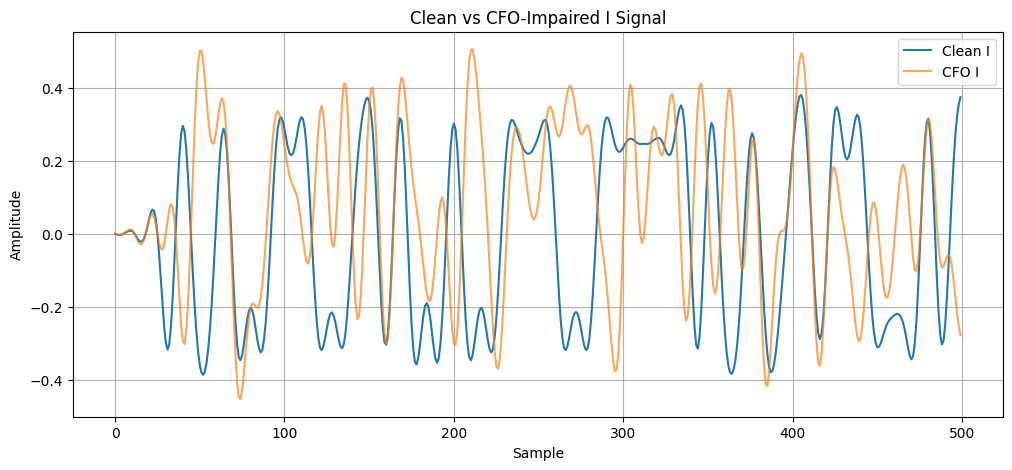

In [74]:
num_plot_samples = 500

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:num_plot_samples]),
    label="Clean I"
)

plt.plot(
    np.real(cfo_signal[:num_plot_samples]),
    label="CFO I",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title("Clean vs CFO-Impaired I Signal")

plt.grid()
plt.legend()

plt.show()

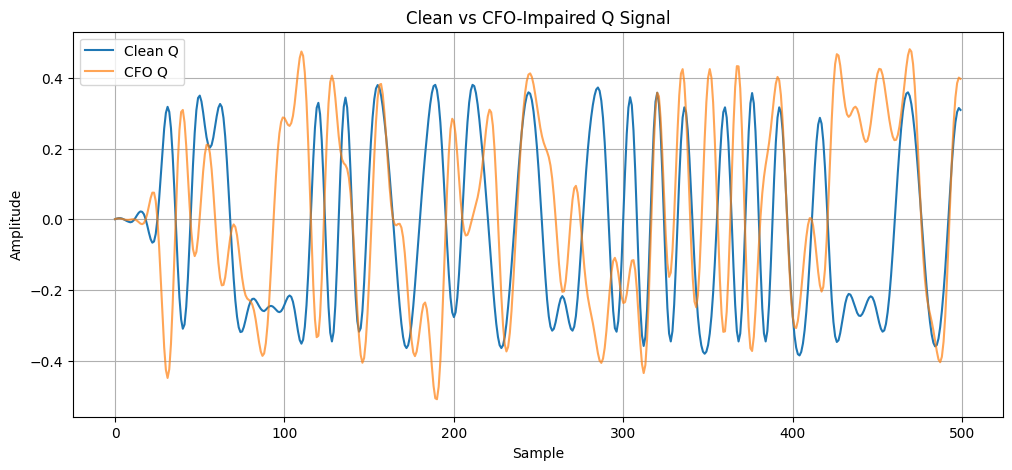

In [75]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.imag(waveform[:num_plot_samples]),
    label="Clean Q"
)

plt.plot(
    np.imag(cfo_signal[:num_plot_samples]),
    label="CFO Q",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title("Clean vs CFO-Impaired Q Signal")

plt.grid()
plt.legend()

plt.show()

In [76]:
sps = 8
span = 8

group_delay = (span * sps) // 2

clean_symbols = waveform[
    group_delay::sps
]

cfo_symbols = cfo_signal[
    group_delay::sps
]

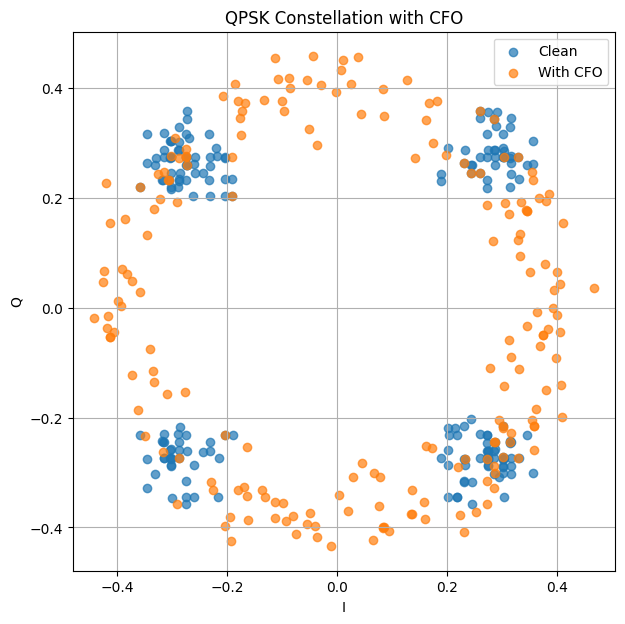

In [77]:
plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(clean_symbols),
    np.imag(clean_symbols),
    label="Clean",
    alpha=0.7
)

plt.scatter(
    np.real(cfo_symbols),
    np.imag(cfo_symbols),
    label="With CFO",
    alpha=0.7
)

plt.xlabel("I")
plt.ylabel("Q")

plt.title("QPSK Constellation with CFO")

plt.axis("equal")
plt.grid()
plt.legend()

plt.show()

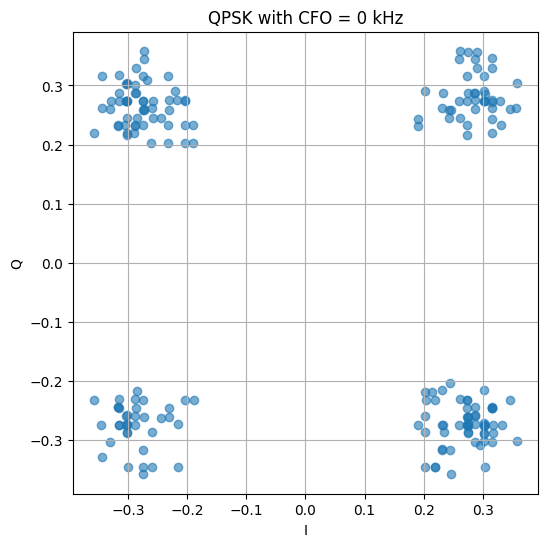

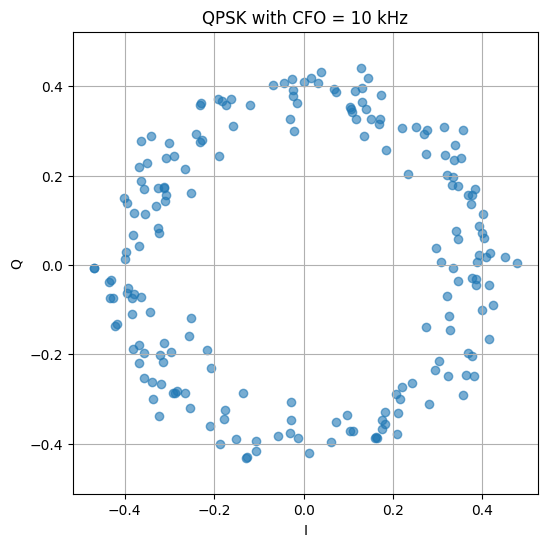

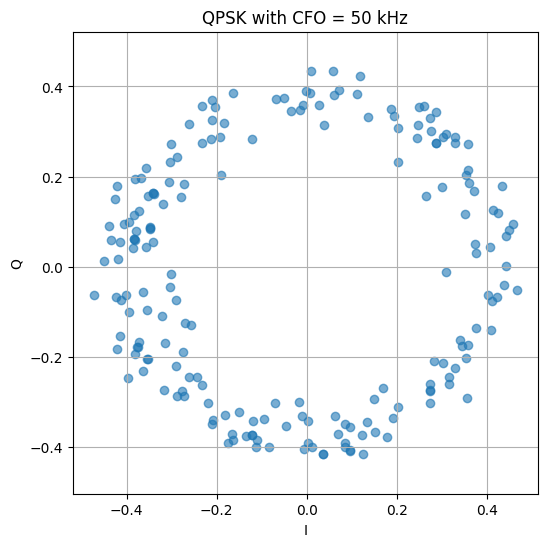

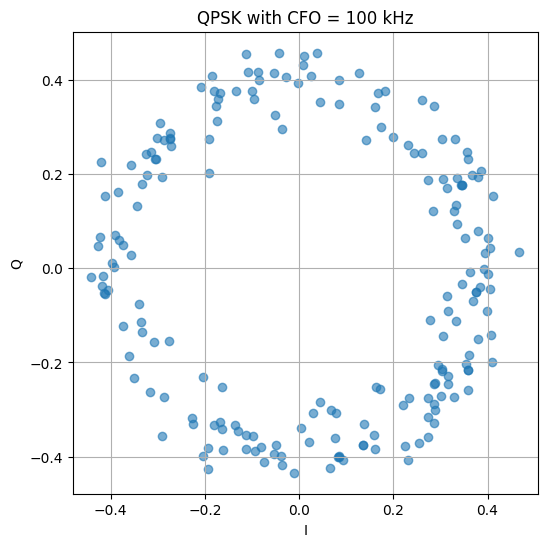

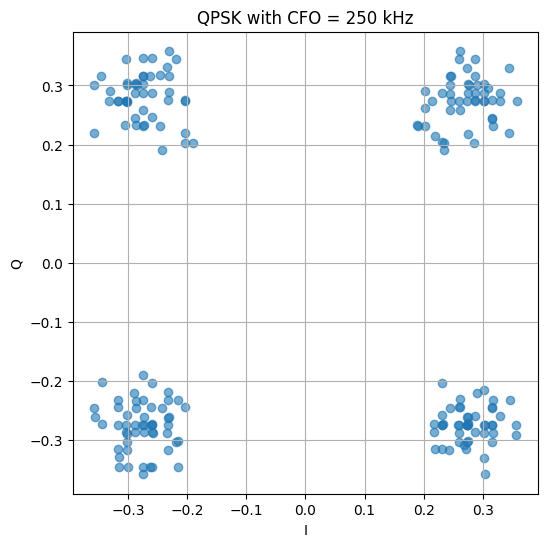

In [78]:
cfo_values = [
    0,
    10e3,
    50e3,
    100e3,
    250e3
]

for cfo_hz in cfo_values:

    cfo_signal = apply_cfo(
        waveform,
        cfo_hz=cfo_hz,
        sample_rate_hz=sample_rate_hz
    )

    cfo_symbols = cfo_signal[
        group_delay::sps
    ]

    plt.figure(figsize=(6, 6))

    plt.scatter(
        np.real(cfo_symbols),
        np.imag(cfo_symbols),
        alpha=0.6
    )

    plt.xlabel("I")
    plt.ylabel("Q")

    plt.title(
        f"QPSK with CFO = {cfo_hz / 1e3:.0f} kHz"
    )

    plt.axis("equal")
    plt.grid()

    plt.show()

In [79]:
cfo_signal = apply_cfo(
    waveform,
    cfo_hz=100e3,
    sample_rate_hz=sample_rate_hz,
    phase_rad=np.pi / 6
)

In [80]:
rng = np.random.default_rng(123)

phase_signal, phase_used = random_phase_offset(
    waveform,
    rng=rng
)

cfo_signal = apply_cfo(
    phase_signal,
    cfo_hz=100e3,
    sample_rate_hz=sample_rate_hz
)

noisy_signal, noise = add_awgn(
    cfo_signal,
    snr_db=10,
    rng=rng
)

print(
    "Random phase:",
    np.degrees(phase_used),
    "degrees"
)

Random phase: 65.64667076933165 degrees


In [81]:
test_cfo_values = [
    -250e3,
    -100e3,
    -50e3,
    0,
    50e3,
    100e3,
    250e3
]

for cfo_hz in test_cfo_values:

    cfo_signal = apply_cfo(
        waveform,
        cfo_hz=cfo_hz,
        sample_rate_hz=sample_rate_hz
    )

    rotation = cfo_signal / waveform

    measured_phase = np.unwrap(
        np.angle(rotation)
    )

    measured_increment = np.mean(
        np.diff(measured_phase)
    )

    expected_increment = (
        2 * np.pi
        * cfo_hz
        / sample_rate_hz
    )

    assert np.isclose(
        measured_increment,
        expected_increment,
        atol=1e-10
    )

    magnitude_error = np.max(
        np.abs(
            np.abs(cfo_signal)
            - np.abs(waveform)
        )
    )

    assert magnitude_error < 1e-10


print("All CFO sanity checks passed.")

All CFO sanity checks passed.


In [82]:
from channel.timing import apply_fractional_timing_offset

In [83]:
import numpy as np

rng = np.random.default_rng(42)

num_symbols = 200

bits = rng.integers(
    0,
    2,
    size=num_symbols * 2
)

symbols = qpsk_modulate(bits)

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=8
)

In [84]:
zero_offset_signal = apply_fractional_timing_offset(
    waveform,
    offset_samples=0.0
)

error = np.max(
    np.abs(
        zero_offset_signal - waveform
    )
)

print("Maximum error:", error)

Maximum error: 0.0


In [85]:
assert error < 1e-12

print("Zero timing-offset test passed.")

Zero timing-offset test passed.


In [86]:
offset_samples = 0.5

shifted_waveform = apply_fractional_timing_offset(
    waveform,
    offset_samples
)

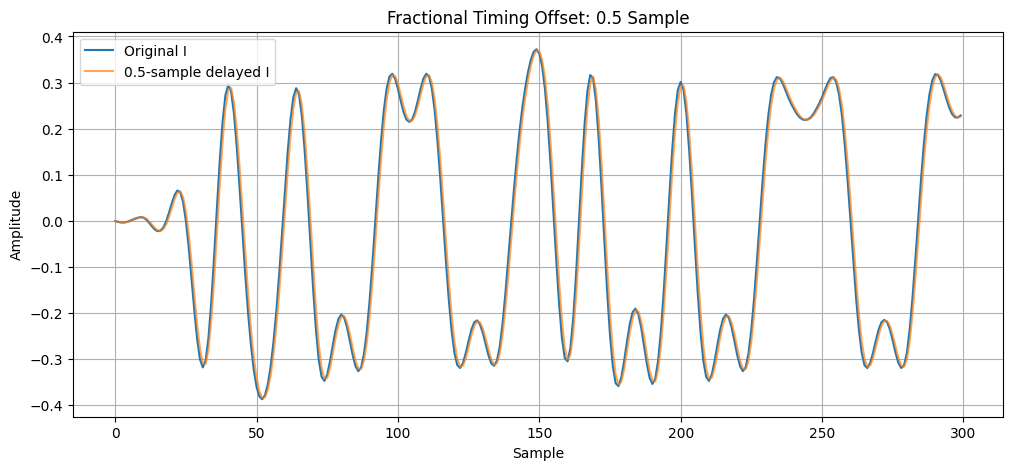

In [87]:
num_plot_samples = 300

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:num_plot_samples]),
    label="Original I"
)

plt.plot(
    np.real(shifted_waveform[:num_plot_samples]),
    label="0.5-sample delayed I",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    "Fractional Timing Offset: 0.5 Sample"
)

plt.grid()
plt.legend()

plt.show()

In [88]:
test_signal = np.array([
    0,
    10,
    20,
    30
], dtype=float)

In [89]:
test_complex = test_signal.astype(np.complex128)

shifted_test = apply_fractional_timing_offset(
    test_complex,
    offset_samples=0.5
)

print("Original:")
print(test_signal)

print("\nShifted:")
print(np.real(shifted_test))

Original:
[ 0. 10. 20. 30.]

Shifted:
[ 0.  5. 15. 25.]


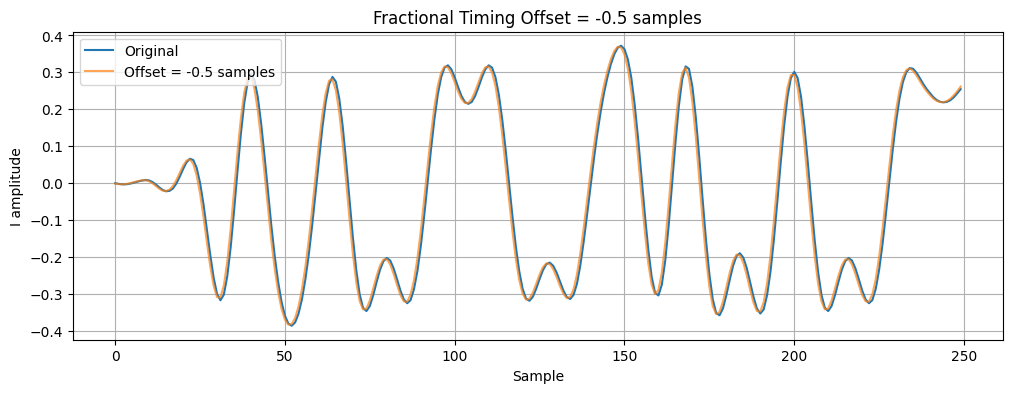

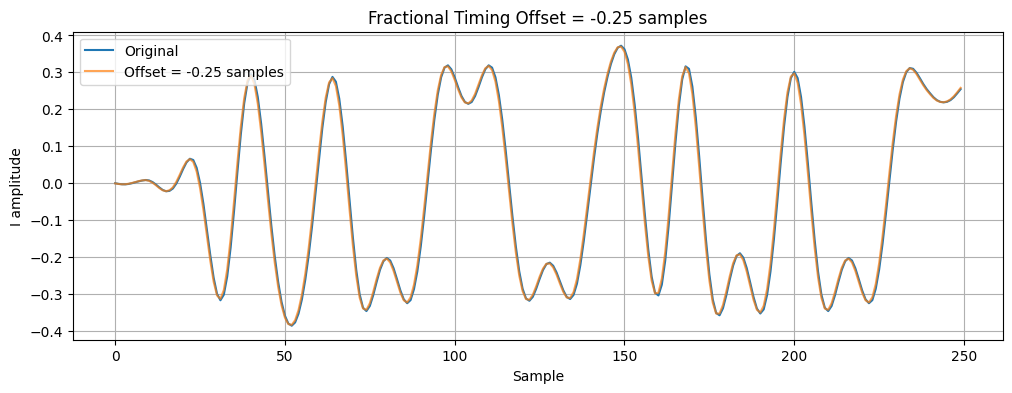

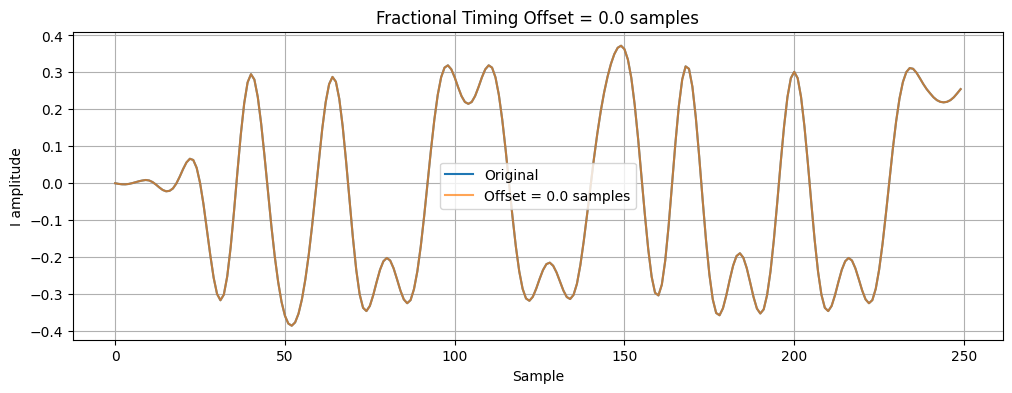

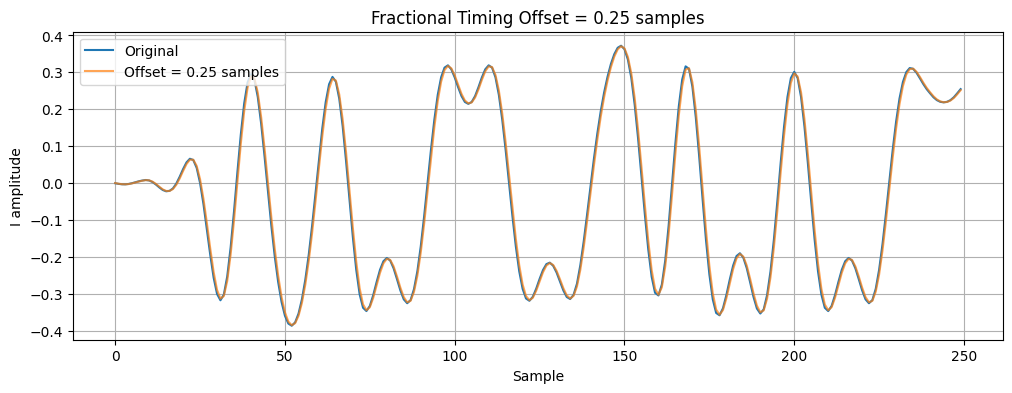

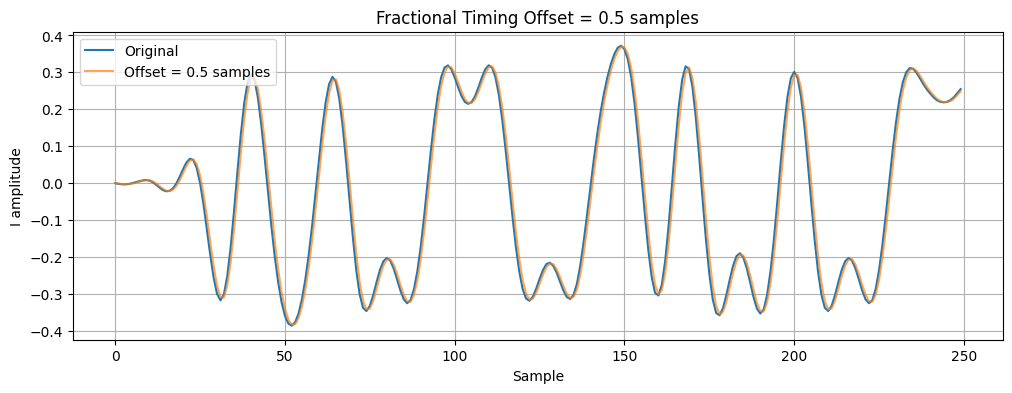

In [90]:
offset_values = [
    -0.5,
    -0.25,
    0.0,
    0.25,
    0.5
]

for offset in offset_values:

    shifted = apply_fractional_timing_offset(
        waveform,
        offset
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        np.real(waveform[:250]),
        label="Original"
    )

    plt.plot(
        np.real(shifted[:250]),
        label=f"Offset = {offset} samples",
        alpha=0.7
    )

    plt.xlabel("Sample")
    plt.ylabel("I amplitude")

    plt.title(
        f"Fractional Timing Offset = {offset} samples"
    )

    plt.grid()
    plt.legend()

    plt.show()

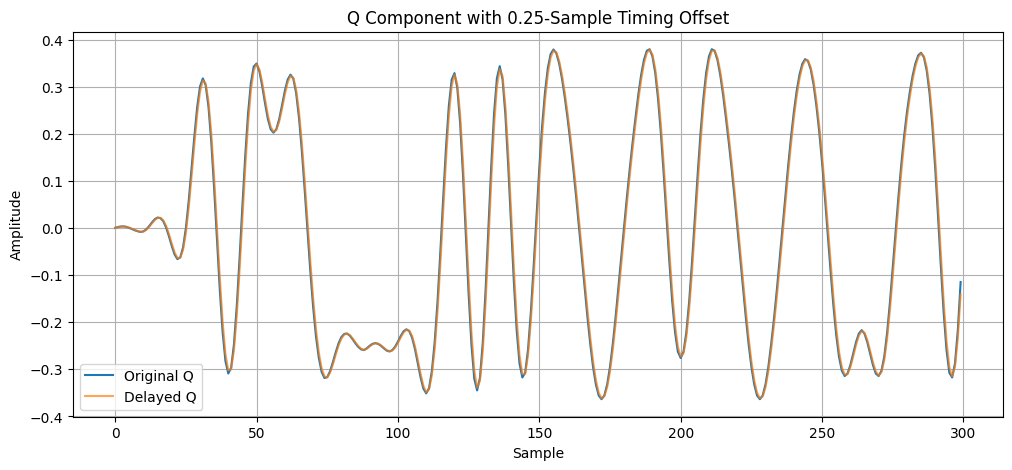

In [91]:
offset_samples = 0.25

shifted_waveform = apply_fractional_timing_offset(
    waveform,
    offset_samples
)

plt.figure(figsize=(12, 5))

plt.plot(
    np.imag(waveform[:300]),
    label="Original Q"
)

plt.plot(
    np.imag(shifted_waveform[:300]),
    label="Delayed Q",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    "Q Component with 0.25-Sample Timing Offset"
)

plt.grid()
plt.legend()

plt.show()

In [92]:
sps = 8
span = 8

group_delay = (span * sps) // 2

clean_symbols = waveform[
    group_delay::sps
]

shifted_symbols = shifted_waveform[
    group_delay::sps
]

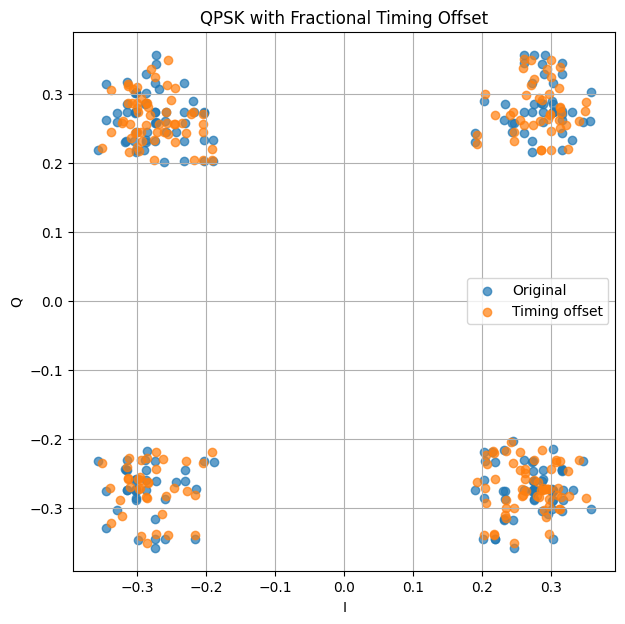

In [93]:
plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(clean_symbols),
    np.imag(clean_symbols),
    label="Original",
    alpha=0.7
)

plt.scatter(
    np.real(shifted_symbols),
    np.imag(shifted_symbols),
    label="Timing offset",
    alpha=0.7
)

plt.xlabel("I")
plt.ylabel("Q")

plt.title(
    "QPSK with Fractional Timing Offset"
)

plt.axis("equal")
plt.grid()
plt.legend()

plt.show()

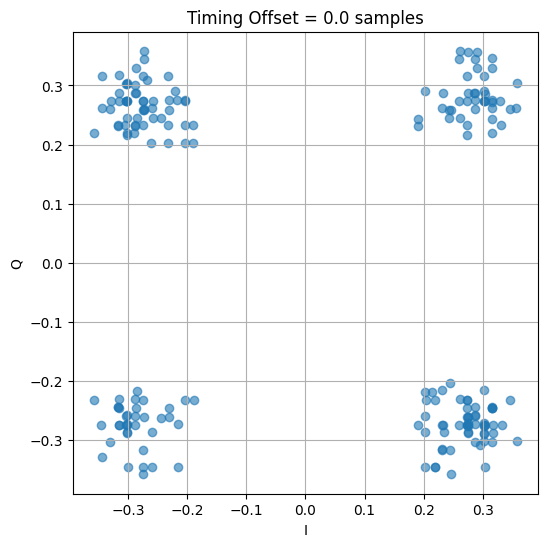

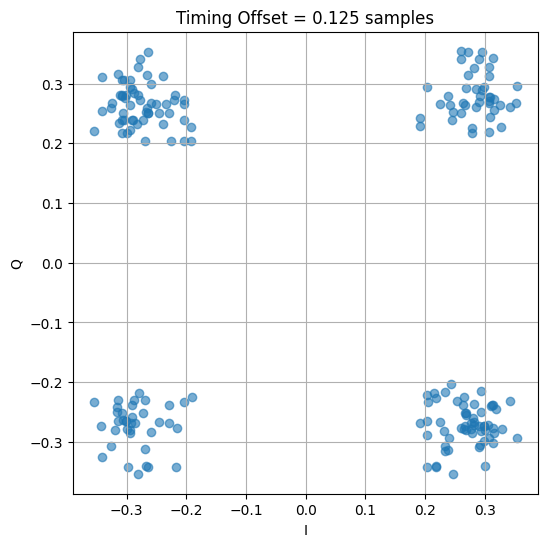

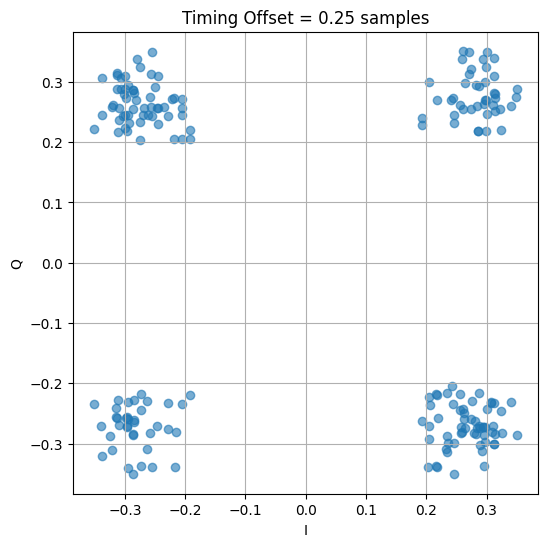

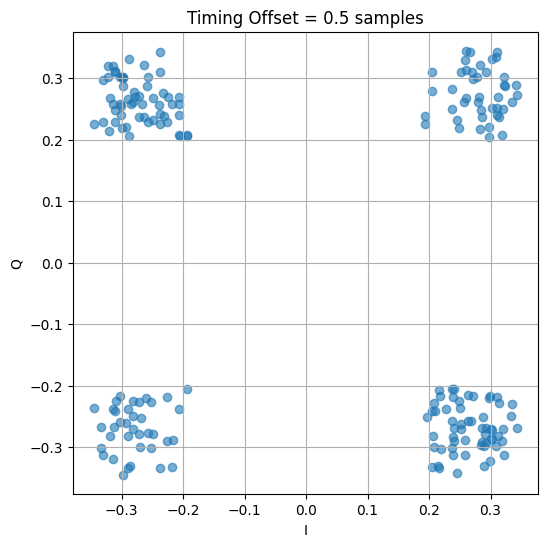

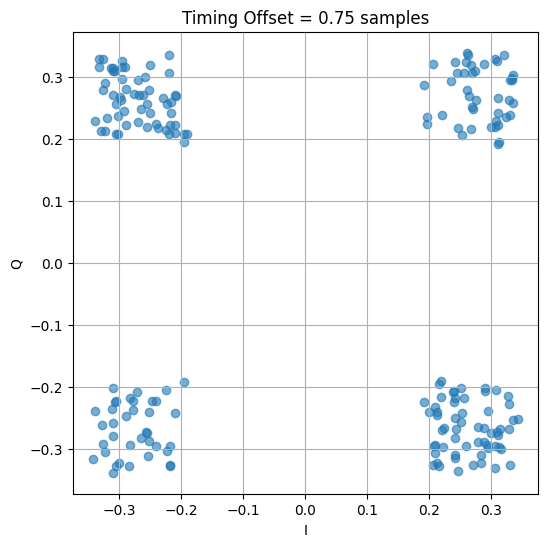

In [94]:
offset_values = [
    0.0,
    0.125,
    0.25,
    0.5,
    0.75
]

for offset in offset_values:

    shifted = apply_fractional_timing_offset(
        waveform,
        offset
    )

    shifted_symbols = shifted[
        group_delay::sps
    ]

    plt.figure(figsize=(6, 6))

    plt.scatter(
        np.real(shifted_symbols),
        np.imag(shifted_symbols),
        alpha=0.6
    )

    plt.xlabel("I")
    plt.ylabel("Q")

    plt.title(
        f"Timing Offset = {offset} samples"
    )

    plt.axis("equal")
    plt.grid()

    plt.show()

In [95]:
assert np.iscomplexobj(shifted_waveform)

print("Complex-signal test passed.")

Complex-signal test passed.


In [96]:
assert np.all(
    np.isfinite(
        shifted_waveform
    )
)

print("Finite-value test passed.")

Finite-value test passed.


In [97]:
assert len(shifted_waveform) == len(waveform)

print("Output-length test passed.")

Output-length test passed.


In [98]:
kind="linear"

In [99]:
test_offsets = [
    -0.5,
    -0.25,
    0.0,
    0.25,
    0.5
]

for offset in test_offsets:

    shifted = apply_fractional_timing_offset(
        waveform,
        offset
    )

    # Must remain complex
    assert np.iscomplexobj(shifted)

    # Must preserve length
    assert len(shifted) == len(waveform)

    # Must not contain NaN/Inf
    assert np.all(
        np.isfinite(shifted)
    )


print(
    "All fractional timing-offset sanity checks passed."
)

All fractional timing-offset sanity checks passed.


In [100]:
zero_shifted = apply_fractional_timing_offset(
    waveform,
    0.0
)

assert np.allclose(
    zero_shifted,
    waveform,
    atol=1e-12
)

print(
    "Zero-offset identity test passed."
)

Zero-offset identity test passed.


In [101]:
from channel.sample_rate import apply_sample_rate_offset

print("SRO function imported successfully.")

SRO function imported successfully.


In [102]:
import numpy as np
import matplotlib.pyplot as plt

from signal_generation.modulation import generate_bits, modulate
from signal_generation.pulse_shaping import pulse_shape

rng = np.random.default_rng(42)

num_bits = 600

bits = generate_bits(num_bits, rng)

symbols = modulate(bits, "QPSK")

sps = 8

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=sps
)

print("Number of symbols:", len(symbols))
print("Waveform samples:", len(waveform))

Number of symbols: 300
Waveform samples: 2400


In [103]:
symbol_rate = 1e6
sps = 8

sample_rate = symbol_rate * sps

print("Sample rate:", sample_rate, "Hz")

Sample rate: 8000000.0 Hz


In [104]:
sro_0 = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=0
)

print("Input length :", len(waveform))
print("Output length:", len(sro_0))

print(
    "Maximum error:",
    np.max(np.abs(waveform - sro_0))
)

Input length : 2400
Output length: 2400
Maximum error: 3.611706891580313e-14


In [105]:
sro_ppm = 50

In [106]:
sro_50 = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=50
)

print("Input length :", len(waveform))
print("Output length:", len(sro_50))

Input length : 2400
Output length: 2400


In [107]:
sro_minus_50 = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=-50
)

print("Input length :", len(waveform))
print("Output length:", len(sro_minus_50))

Input length : 2400
Output length: 2399


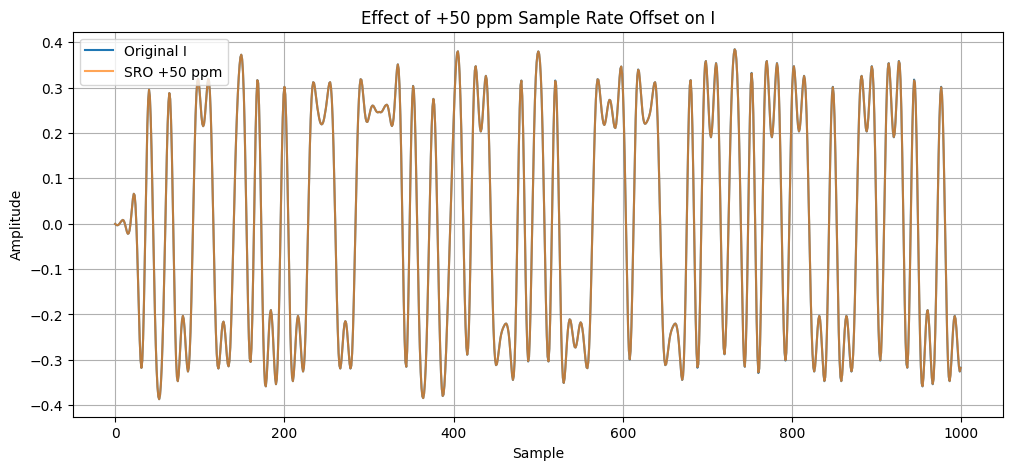

In [108]:
N = min(1000, len(waveform))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original I"
)

plt.plot(
    np.real(sro_50[:N]),
    label="SRO +50 ppm",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Effect of +50 ppm Sample Rate Offset on I")
plt.legend()
plt.grid()

plt.show()

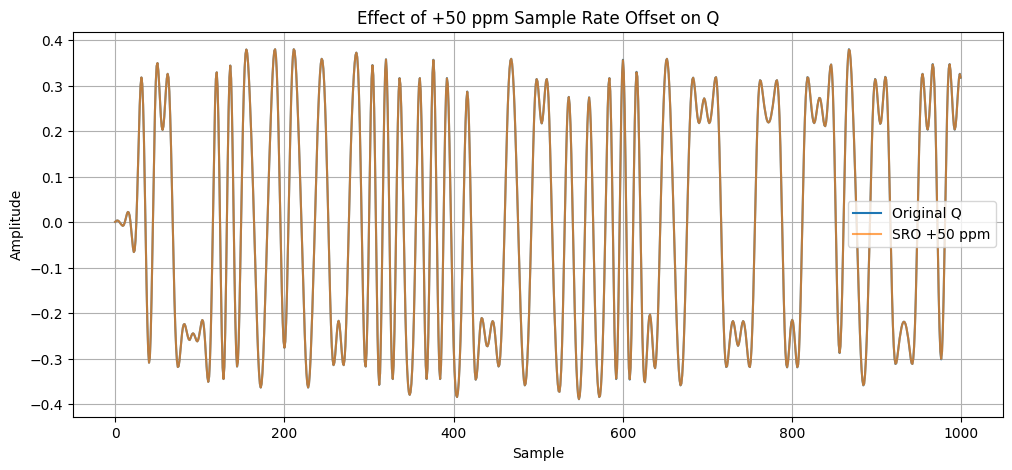

In [109]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.imag(waveform[:N]),
    label="Original Q"
)

plt.plot(
    np.imag(sro_50[:N]),
    label="SRO +50 ppm",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Effect of +50 ppm Sample Rate Offset on Q")
plt.legend()
plt.grid()

plt.show()

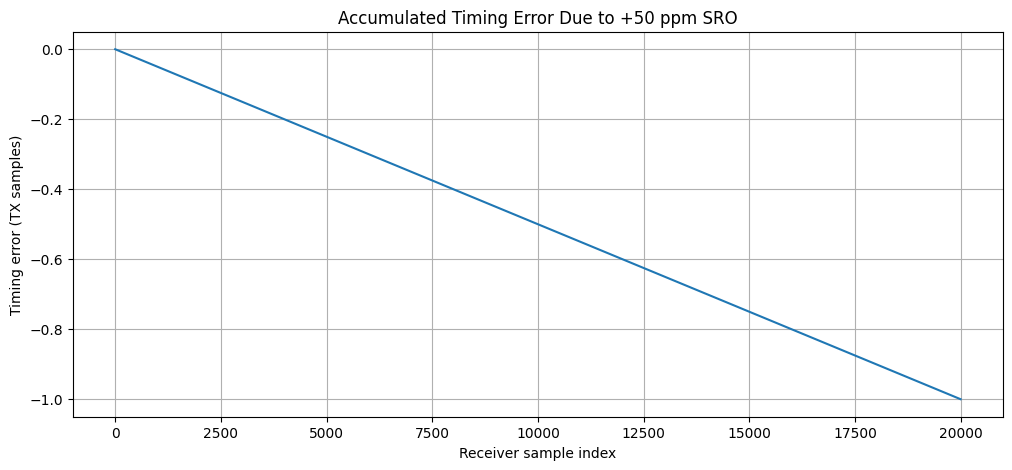

In [110]:
sro_ppm = 50
epsilon = sro_ppm * 1e-6

n = np.arange(20000)

source_indices = n / (1 + epsilon)

timing_error = source_indices - n

plt.figure(figsize=(12, 5))

plt.plot(timing_error)

plt.xlabel("Receiver sample index")
plt.ylabel("Timing error (TX samples)")
plt.title("Accumulated Timing Error Due to +50 ppm SRO")
plt.grid()

plt.show()

In [111]:
fixed_offset = apply_fractional_timing_offset(
    waveform,
    offset_samples=0.5
)

In [112]:
sro_signal = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=50
)

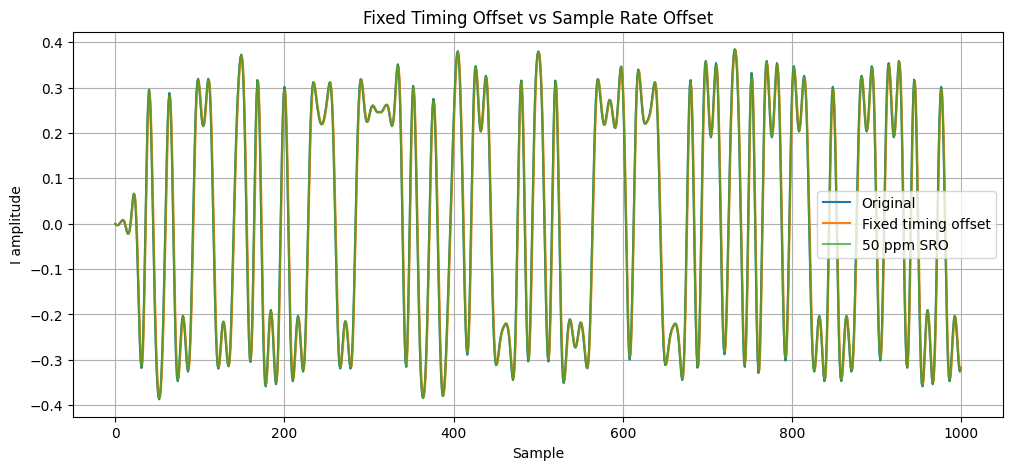

In [113]:
N = min(1000, len(waveform))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(fixed_offset[:N]),
    label="Fixed timing offset"
)

plt.plot(
    np.real(sro_signal[:N]),
    label="50 ppm SRO",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")
plt.title("Fixed Timing Offset vs Sample Rate Offset")
plt.legend()
plt.grid()

plt.show()

In [114]:
sro_values = [-100, -50, 0, 50, 100]

signals = {}

for sro in sro_values:
    signals[sro] = apply_sample_rate_offset(
        waveform,
        sample_rate_hz=sample_rate,
        sro_ppm=sro
    )

    print(
        f"SRO = {sro:>4} ppm | "
        f"length = {len(signals[sro])}"
    )

SRO = -100 ppm | length = 2399
SRO =  -50 ppm | length = 2399
SRO =    0 ppm | length = 2400
SRO =   50 ppm | length = 2400
SRO =  100 ppm | length = 2400


In [115]:
assert np.iscomplexobj(sro_50)

print("Complex output test passed.")

Complex output test passed.


In [116]:
assert np.all(np.isfinite(sro_50))

print("Finite-value test passed.")

Finite-value test passed.


In [117]:
assert len(sro_0) == len(waveform)

error = np.max(
    np.abs(sro_0 - waveform)
)

assert error < 1e-10

print("Zero-SRO identity test passed.")

Zero-SRO identity test passed.


In [118]:
sro_positive = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=100
)

sro_negative = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=sample_rate,
    sro_ppm=-100
)

assert np.all(np.isfinite(sro_positive))
assert np.all(np.isfinite(sro_negative))

print("Positive/negative SRO tests passed.")

Positive/negative SRO tests passed.


In [119]:
from channel.multipath import apply_multipath

print("Multipath function imported successfully.")

Multipath function imported successfully.


In [120]:
import numpy as np
import matplotlib.pyplot as plt

from signal_generation.modulation import generate_bits, modulate
from signal_generation.pulse_shaping import pulse_shape

rng = np.random.default_rng(42)

num_bits = 600

bits = generate_bits(num_bits, rng)

symbols = modulate(
    bits,
    "QPSK"
)

sps = 8

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=sps
)

print("Symbols:", len(symbols))
print("Waveform samples:", len(waveform))

Symbols: 300
Waveform samples: 2400


In [121]:
multipath_signal = apply_multipath(
    waveform,
    path_gains=[1.0, 0.5],
    path_delays=[0, 8]
)

print("Input length :", len(waveform))
print("Output length:", len(multipath_signal))

Input length : 2400
Output length: 2408


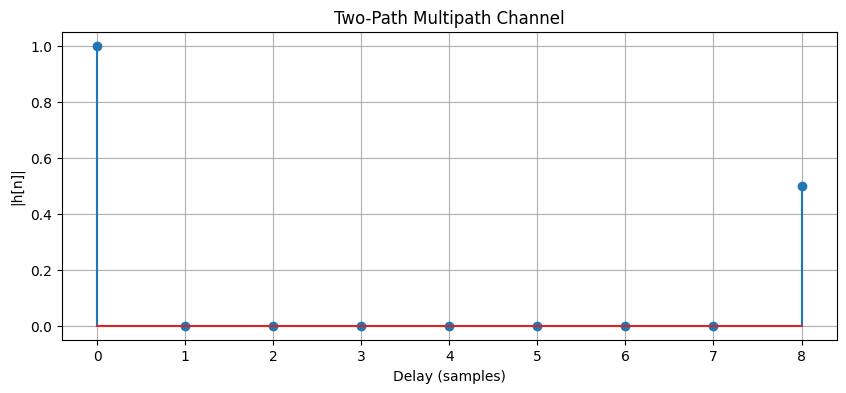

In [122]:
path_gains = np.array(
    [1.0, 0.5],
    dtype=np.complex128
)

path_delays = np.array([0, 8])

max_delay = np.max(path_delays)

h = np.zeros(
    max_delay + 1,
    dtype=np.complex128
)

for gain, delay in zip(path_gains, path_delays):
    h[delay] += gain

plt.figure(figsize=(10, 4))

plt.stem(
    np.arange(len(h)),
    np.abs(h)
)

plt.xlabel("Delay (samples)")
plt.ylabel("|h[n]|")
plt.title("Two-Path Multipath Channel")
plt.grid()

plt.show()

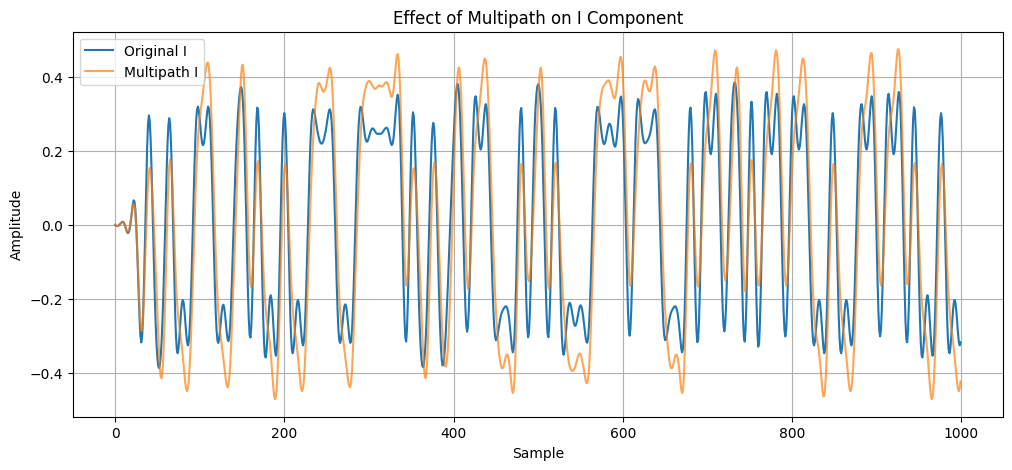

In [123]:
N = min(1000, len(waveform))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original I"
)

plt.plot(
    np.real(multipath_signal[:N]),
    label="Multipath I",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Effect of Multipath on I Component")
plt.legend()
plt.grid()

plt.show()

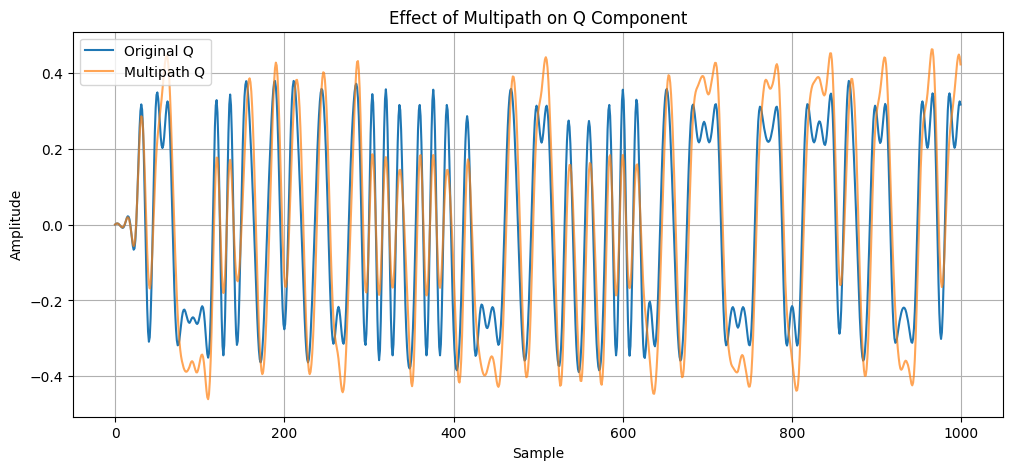

In [124]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.imag(waveform[:N]),
    label="Original Q"
)

plt.plot(
    np.imag(multipath_signal[:N]),
    label="Multipath Q",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")
plt.title("Effect of Multipath on Q Component")
plt.legend()
plt.grid()

plt.show()

In [125]:
direct_path = waveform

delayed_path = np.zeros(
    len(waveform) + 8,
    dtype=np.complex128
)

delayed_path[8:] = 0.5 * waveform

direct_padded = np.zeros_like(delayed_path)
direct_padded[:len(waveform)] = waveform

combined = direct_padded + delayed_path

In [126]:
difference = np.max(
    np.abs(combined - multipath_signal)
)

print("Maximum difference:", difference)

Maximum difference: 0.0


In [127]:
single_path = apply_multipath(
    waveform,
    path_gains=[1.0],
    path_delays=[0]
)

error = np.max(
    np.abs(single_path - waveform)
)

print("Maximum error:", error)

Maximum error: 0.0


In [128]:
assert np.allclose(
    single_path,
    waveform
)

print("Single-path identity test passed.")

Single-path identity test passed.


In [129]:
delay = 10

delayed_signal = apply_multipath(
    waveform,
    path_gains=[1.0],
    path_delays=[delay]
)

In [130]:
expected = np.zeros(
    len(waveform) + delay,
    dtype=np.complex128
)

expected[delay:] = waveform

assert np.allclose(
    delayed_signal,
    expected
)

print("Pure-delay test passed.")

Pure-delay test passed.


In [131]:
three_path_signal = apply_multipath(
    waveform,
    path_gains=[
        1.0,
        0.5,
        0.25
    ],
    path_delays=[
        0,
        4,
        12
    ]
)

print(
    "Three-path output length:",
    len(three_path_signal)
)

Three-path output length: 2412


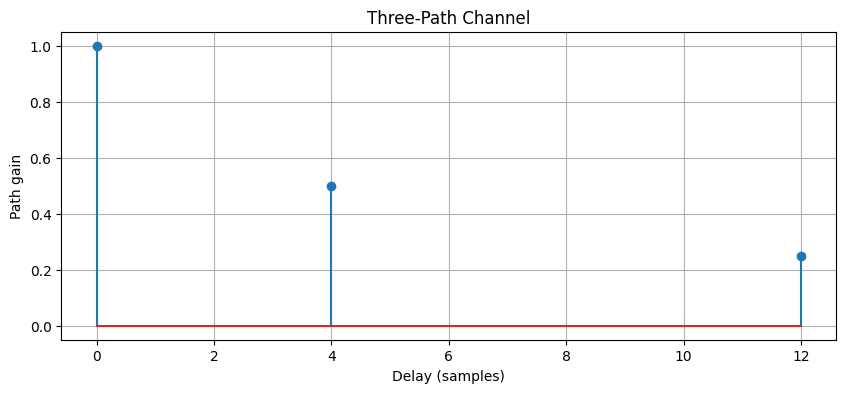

In [132]:
path_gains = np.array([1.0, 0.5, 0.25])
path_delays = np.array([0, 4, 12])

plt.figure(figsize=(10, 4))

plt.stem(
    path_delays,
    path_gains
)

plt.xlabel("Delay (samples)")
plt.ylabel("Path gain")
plt.title("Three-Path Channel")
plt.grid()

plt.show()

In [133]:
complex_path_signal = apply_multipath(
    waveform,
    path_gains=[
        1.0,
        0.5 * np.exp(1j * np.pi / 3)
    ],
    path_delays=[
        0,
        8
    ]
)

print("Complex multipath simulation complete.")

Complex multipath simulation complete.


In [134]:
usable_length = min(
    len(waveform),
    len(multipath_signal)
)

clean_part = waveform[:usable_length]
multipath_part = multipath_signal[:usable_length]

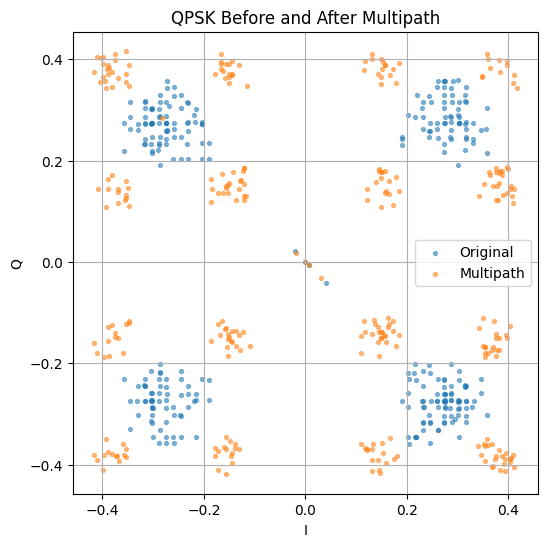

In [135]:
plt.figure(figsize=(6, 6))

plt.scatter(
    np.real(clean_part[::sps]),
    np.imag(clean_part[::sps]),
    s=8,
    alpha=0.5,
    label="Original"
)

plt.scatter(
    np.real(multipath_part[::sps]),
    np.imag(multipath_part[::sps]),
    s=8,
    alpha=0.5,
    label="Multipath"
)

plt.xlabel("I")
plt.ylabel("Q")
plt.title("QPSK Before and After Multipath")
plt.axis("equal")
plt.grid()
plt.legend()

plt.show()

In [136]:
delays = [1, 2, 4, 8, 16]

signals = {}

for delay in delays:
    signals[delay] = apply_multipath(
        waveform,
        path_gains=[1.0, 0.5],
        path_delays=[0, delay]
    )

    print(
        f"Delay = {delay:2d} samples "
        f"= {delay / sps:.2f} symbols"
    )

Delay =  1 samples = 0.12 symbols
Delay =  2 samples = 0.25 symbols
Delay =  4 samples = 0.50 symbols
Delay =  8 samples = 1.00 symbols
Delay = 16 samples = 2.00 symbols


In [137]:
gains = [0.1, 0.25, 0.5, 0.75, 1.0]

for gain in gains:

    test_signal = apply_multipath(
        waveform,
        path_gains=[1.0, gain],
        path_delays=[0, 8]
    )

    print(
        f"Second-path gain = {gain:.2f}, "
        f"output length = {len(test_signal)}"
    )

Second-path gain = 0.10, output length = 2408
Second-path gain = 0.25, output length = 2408
Second-path gain = 0.50, output length = 2408
Second-path gain = 0.75, output length = 2408
Second-path gain = 1.00, output length = 2408


In [138]:
# --------------------------------------------------
# Multipath automated sanity checks
# --------------------------------------------------

# 1. Input must be complex
assert np.iscomplexobj(waveform)

# 2. Single path with gain 1 and delay 0 = identity
single_path = apply_multipath(
    waveform,
    path_gains=[1.0],
    path_delays=[0]
)

assert np.allclose(
    single_path,
    waveform
)

# 3. Pure delay
delay = 5

pure_delay = apply_multipath(
    waveform,
    path_gains=[1.0],
    path_delays=[delay]
)

expected = np.zeros(
    len(waveform) + delay,
    dtype=np.complex128
)

expected[delay:] = waveform

assert np.allclose(
    pure_delay,
    expected
)

# 4. Two-path output must be finite
two_path = apply_multipath(
    waveform,
    path_gains=[1.0, 0.5],
    path_delays=[0, 8]
)

assert np.all(np.isfinite(two_path))

# 5. Three-path output must be finite
three_path = apply_multipath(
    waveform,
    path_gains=[1.0, 0.5, 0.25],
    path_delays=[0, 4, 12]
)

assert np.all(np.isfinite(three_path))

print("All multipath sanity checks passed.")

All multipath sanity checks passed.


In [139]:
from channel.fading import (
    generate_rayleigh_channel,
    generate_rician_channel,
    apply_flat_fading
)

In [140]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

num_bits = 600

bits = generate_bits(
    num_bits,
    rng
)

symbols = modulate(
    bits,
    "QPSK"
)

sps = 8

waveform = pulse_shape(
    symbols,
    beta=0.35,
    span=8,
    sps=sps
)

print("Waveform length:", len(waveform))

Waveform length: 2400


In [141]:
h = generate_rayleigh_channel(
    rng=rng
)

print("h =", h)
print("|h| =", abs(h))
print("Phase =", np.angle(h))

h = (-0.20659622674900846-0.07317725612269216j)
|h| = 0.2191732459050917
Phase = -2.8011773441541896


In [142]:
faded_signal = apply_flat_fading(
    waveform,
    h
)

print("Original length:", len(waveform))
print("Faded length:", len(faded_signal))

Original length: 2400
Faded length: 2400


In [143]:
index = 100

expected = h * waveform[index]
actual = faded_signal[index]

print("Expected:", expected)
print("Actual  :", actual)

print(
    "Error:",
    abs(expected - actual)
)

Expected: (-0.07680068817181052+0.028862555590195814j)
Actual  : (-0.07680068817181053+0.028862555590195814j)
Error: 1.3877787807814457e-17


In [144]:
assert len(faded_signal) == len(waveform)

print("Output-length test passed.")

Output-length test passed.


In [145]:
original_power = np.mean(
    np.abs(waveform) ** 2
)

faded_power = np.mean(
    np.abs(faded_signal) ** 2
)

expected_power = (
    abs(h) ** 2
    * original_power
)

print("Original power:", original_power)
print("Faded power:", faded_power)
print("Expected:", expected_power)

Original power: 0.12353166746319488
Faded power: 0.005934079804624771
Expected: 0.005934079804624772


In [146]:
assert np.isclose(
    faded_power,
    expected_power,
    rtol=1e-10,
    atol=1e-12
)

print("Fading power test passed.")

Fading power test passed.


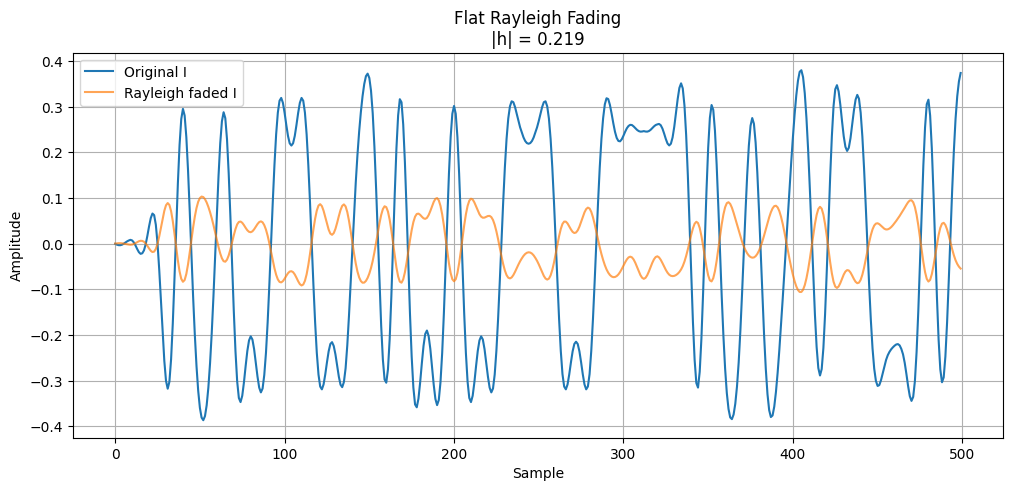

In [147]:
N = min(500, len(waveform))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original I"
)

plt.plot(
    np.real(faded_signal[:N]),
    label="Rayleigh faded I",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("Amplitude")

plt.title(
    f"Flat Rayleigh Fading\n"
    f"|h| = {abs(h):.3f}"
)

plt.grid()
plt.legend()

plt.show()

In [148]:
rng = np.random.default_rng(123)

num_realizations = 10000

rayleigh_coefficients = np.array([
    generate_rayleigh_channel(
        rng=rng
    )
    for _ in range(num_realizations)
])

In [149]:
rayleigh_magnitudes = np.abs(
    rayleigh_coefficients
)

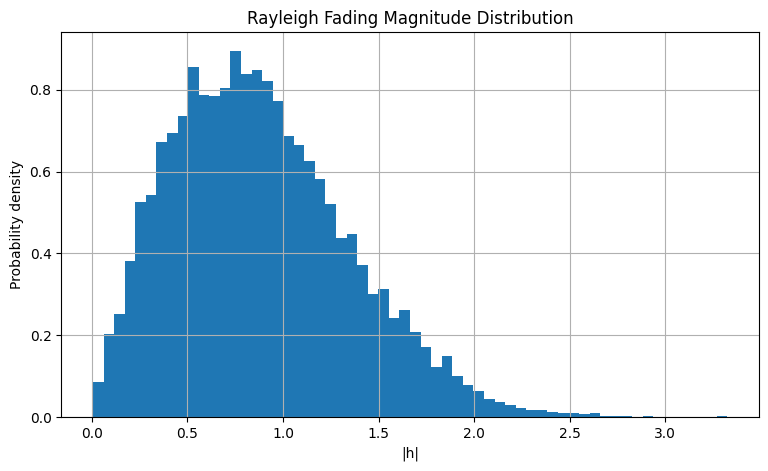

In [150]:
plt.figure(figsize=(9, 5))

plt.hist(
    rayleigh_magnitudes,
    bins=60,
    density=True
)

plt.xlabel("|h|")
plt.ylabel("Probability density")

plt.title(
    "Rayleigh Fading Magnitude Distribution"
)

plt.grid()

plt.show()

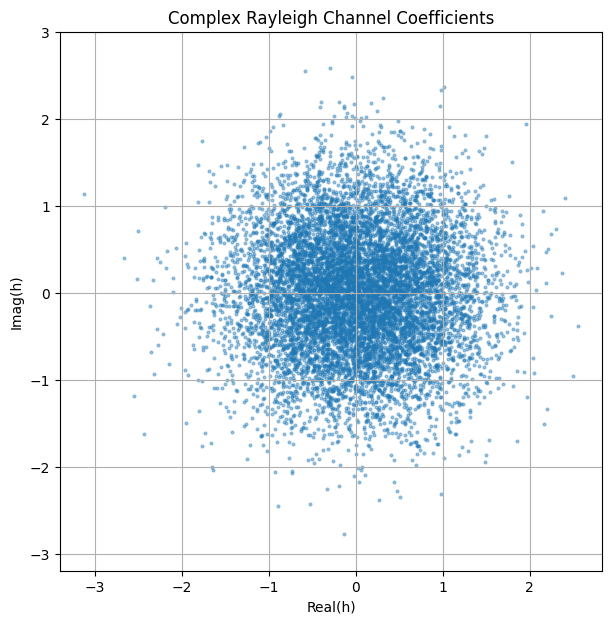

In [151]:
plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(rayleigh_coefficients),
    np.imag(rayleigh_coefficients),
    s=4,
    alpha=0.4
)

plt.xlabel("Real(h)")
plt.ylabel("Imag(h)")

plt.title(
    "Complex Rayleigh Channel Coefficients"
)

plt.axis("equal")
plt.grid()

plt.show()

In [152]:
print(
    "Mean real:",
    np.mean(
        np.real(rayleigh_coefficients)
    )
)

print(
    "Mean imaginary:",
    np.mean(
        np.imag(rayleigh_coefficients)
    )
)

Mean real: 0.007571370736876032
Mean imaginary: 0.00014020787299810636


In [153]:
average_power = np.mean(
    np.abs(rayleigh_coefficients) ** 2
)

print(
    "Average channel power:",
    average_power
)

Average channel power: 0.9976378958615846


In [154]:
h_rician = generate_rician_channel(
    K=5,
    rng=rng
)

print("Rician h:", h_rician)
print("|h|:", abs(h_rician))
print("Phase:", np.angle(h_rician))

Rician h: (1.1223460518882278+0.15851643694956385j)
|h|: 1.133484945189956
Phase: 0.14030864789866343


In [155]:
rician_signal = apply_flat_fading(
    waveform,
    h_rician
)

In [156]:
K = 10

K_dB = 10 * np.log10(K)

print("K =", K)
print("K =", K_dB, "dB")

K = 10
K = 10.0 dB


In [157]:
rng = np.random.default_rng(123)

K = 5

rician_coefficients = np.array([
    generate_rician_channel(
        K=K,
        rng=rng
    )
    for _ in range(num_realizations)
])

rician_magnitudes = np.abs(
    rician_coefficients
)

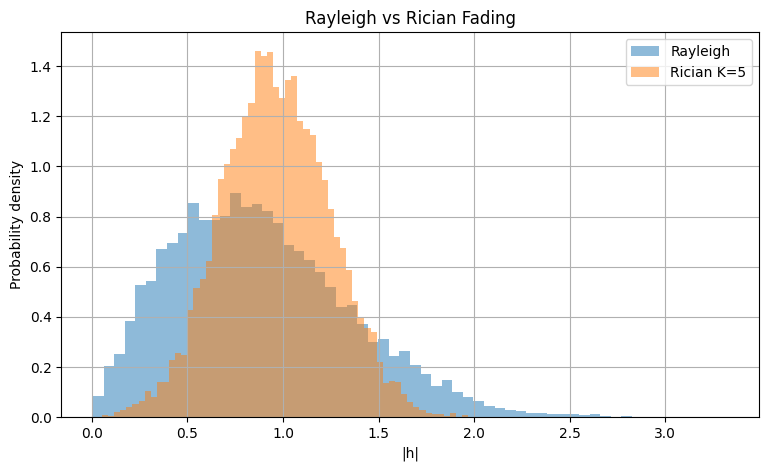

In [158]:
plt.figure(figsize=(9, 5))

plt.hist(
    rayleigh_magnitudes,
    bins=60,
    density=True,
    alpha=0.5,
    label="Rayleigh"
)

plt.hist(
    rician_magnitudes,
    bins=60,
    density=True,
    alpha=0.5,
    label=f"Rician K={K}"
)

plt.xlabel("|h|")
plt.ylabel("Probability density")

plt.title(
    "Rayleigh vs Rician Fading"
)

plt.grid()
plt.legend()

plt.show()

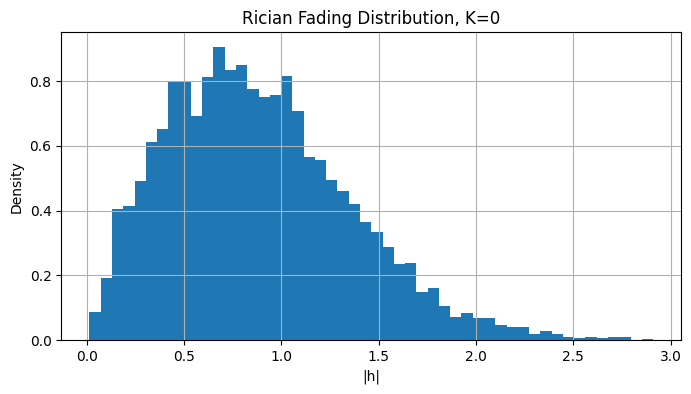

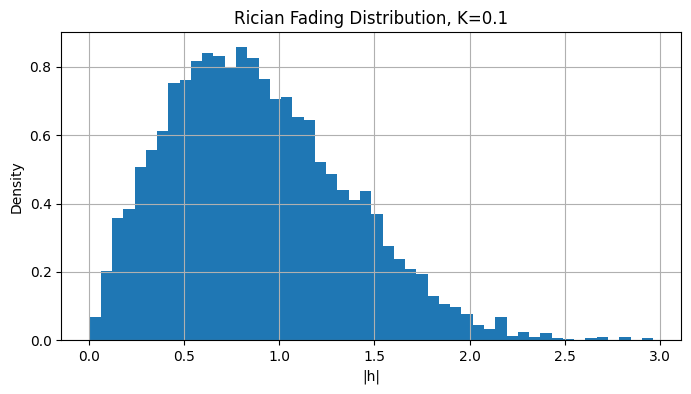

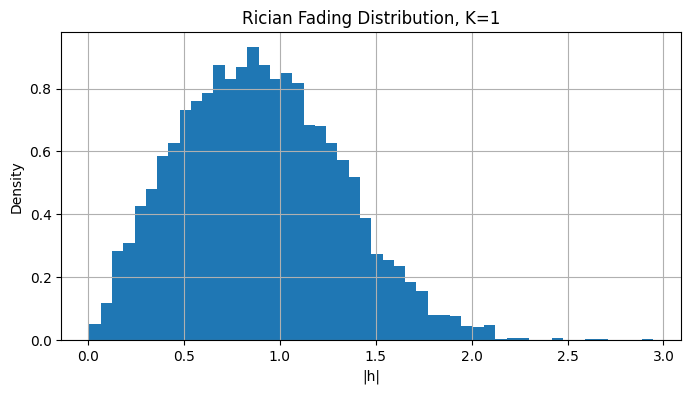

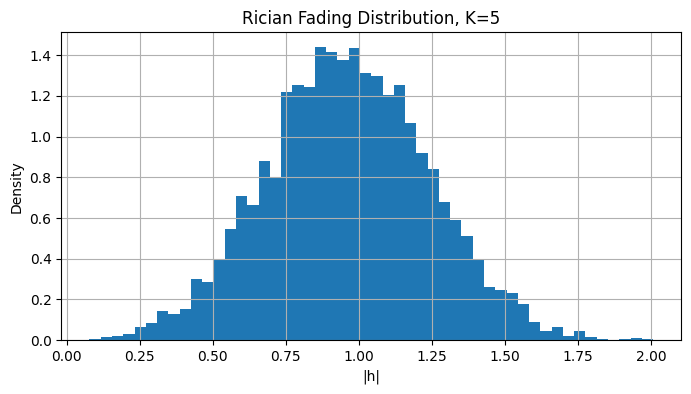

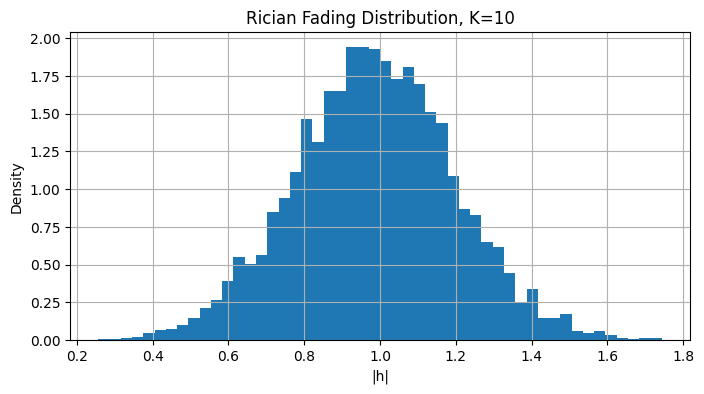

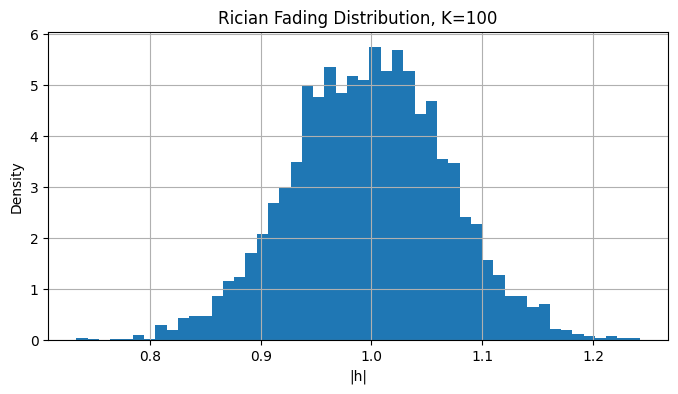

In [159]:
K_values = [
    0,
    0.1,
    1,
    5,
    10,
    100
]

for K in K_values:

    coefficients = np.array([
        generate_rician_channel(
            K=K,
            rng=rng
        )
        for _ in range(5000)
    ])

    magnitudes = np.abs(
        coefficients
    )

    plt.figure(figsize=(8, 4))

    plt.hist(
        magnitudes,
        bins=50,
        density=True
    )

    plt.xlabel("|h|")
    plt.ylabel("Density")

    plt.title(
        f"Rician Fading Distribution, K={K}"
    )

    plt.grid()

    plt.show()

In [160]:
K = 5

h = generate_rician_channel(
    K=K,
    rng=rng
)

rician_signal = apply_flat_fading(
    waveform,
    h
)

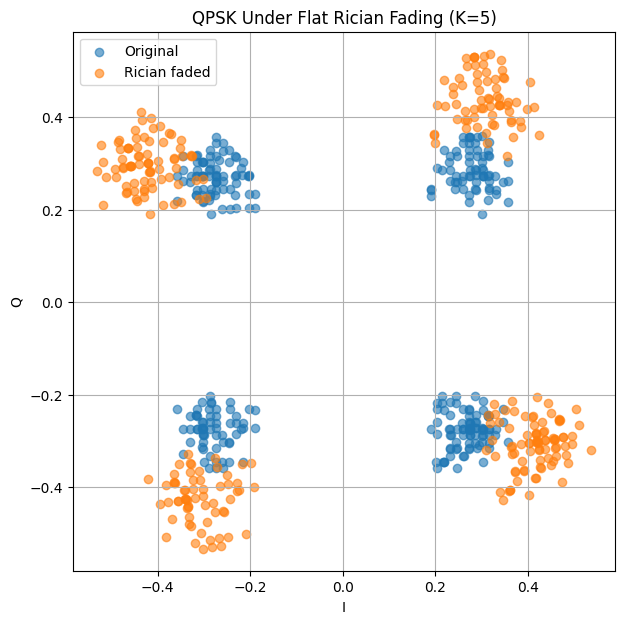

In [161]:
group_delay = (8 * 8) // 2

clean_symbols = waveform[
    group_delay::8
]

rician_symbols = rician_signal[
    group_delay::8
]

plt.figure(figsize=(7, 7))

plt.scatter(
    np.real(clean_symbols),
    np.imag(clean_symbols),
    alpha=0.6,
    label="Original"
)

plt.scatter(
    np.real(rician_symbols),
    np.imag(rician_symbols),
    alpha=0.6,
    label="Rician faded"
)

plt.xlabel("I")
plt.ylabel("Q")

plt.title(
    f"QPSK Under Flat Rician Fading (K={K})"
)

plt.axis("equal")
plt.grid()
plt.legend()

plt.show()

In [162]:
# --------------------------------------------------
# Fading sanity checks
# --------------------------------------------------

rng = np.random.default_rng(42)

# Rayleigh coefficient
h_rayleigh = generate_rayleigh_channel(
    rng=rng
)

assert np.iscomplexobj(h_rayleigh)

# Flat fading
faded = apply_flat_fading(
    waveform,
    h_rayleigh
)

assert len(faded) == len(waveform)

assert np.all(
    np.isfinite(faded)
)

# Power relationship
original_power = np.mean(
    np.abs(waveform) ** 2
)

faded_power = np.mean(
    np.abs(faded) ** 2
)

expected_power = (
    abs(h_rayleigh) ** 2
    * original_power
)

assert np.isclose(
    faded_power,
    expected_power,
    rtol=1e-10,
    atol=1e-12
)

# Rician
h_rician = generate_rician_channel(
    K=5,
    rng=rng
)

assert np.iscomplexobj(h_rician)

rician_signal = apply_flat_fading(
    waveform,
    h_rician
)

assert len(rician_signal) == len(waveform)

assert np.all(
    np.isfinite(rician_signal)
)

print("All fading sanity checks passed.")

All fading sanity checks passed.


In [163]:
from channel.fading import generate_correlated_rayleigh_channel

rng = np.random.default_rng(42)

num_samples = len(waveform)

h = generate_correlated_rayleigh_channel(
    num_samples=num_samples,
    rho=0.99,
    rng=rng
)

print("Channel length:", len(h))
print("Signal length :", len(waveform))

Channel length: 2400
Signal length : 2400


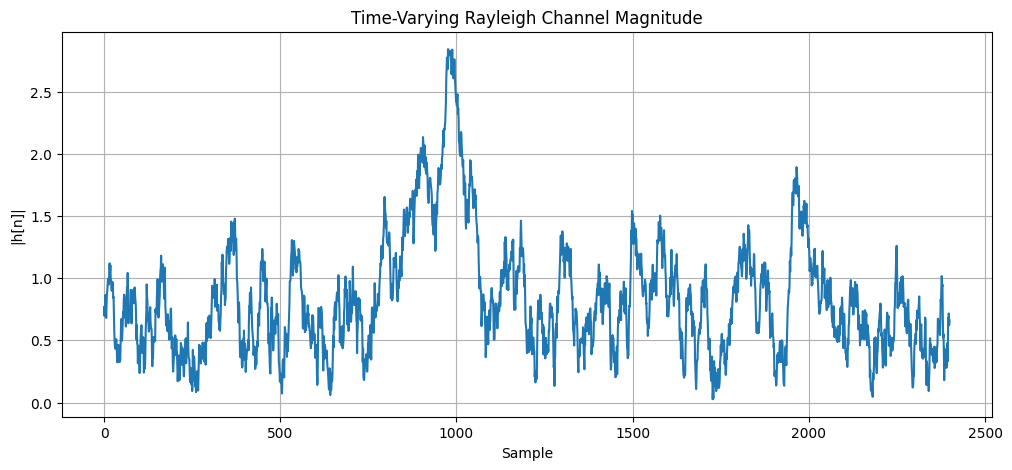

In [164]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.abs(h)
)

plt.xlabel("Sample")
plt.ylabel("|h[n]|")

plt.title(
    "Time-Varying Rayleigh Channel Magnitude"
)

plt.grid()

plt.show()

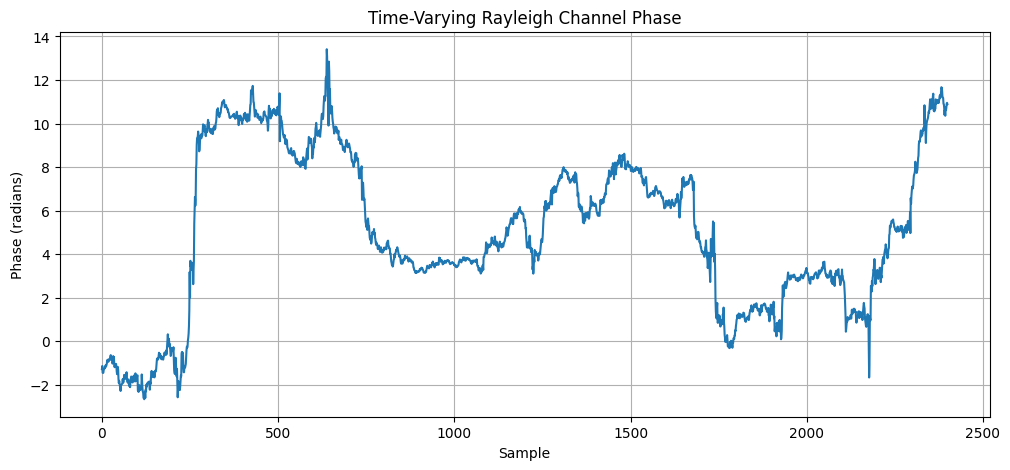

In [165]:
plt.figure(figsize=(12, 5))

plt.plot(
    np.unwrap(np.angle(h))
)

plt.xlabel("Sample")
plt.ylabel("Phase (radians)")

plt.title(
    "Time-Varying Rayleigh Channel Phase"
)

plt.grid()

plt.show()

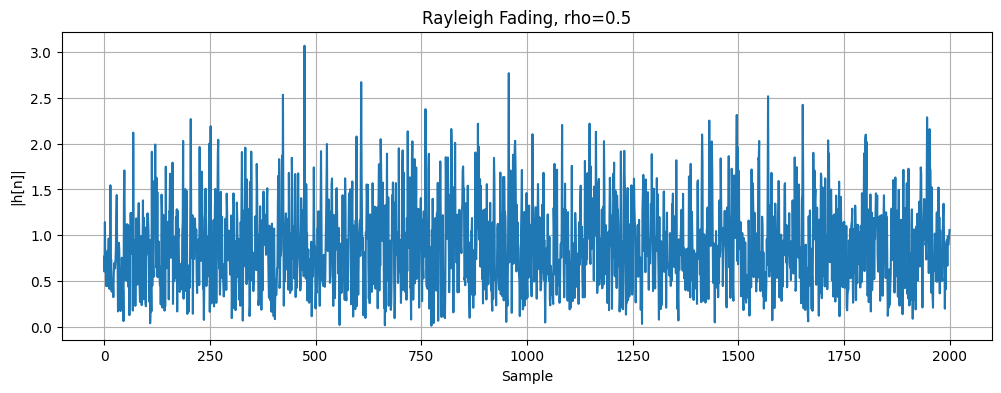

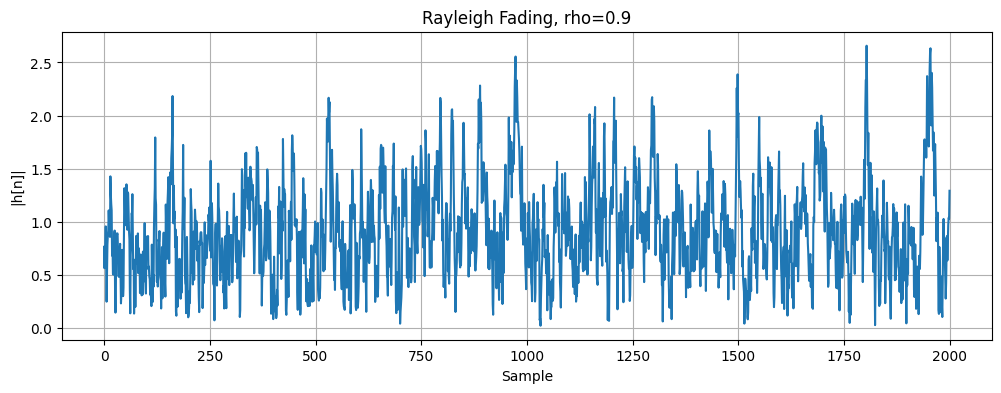

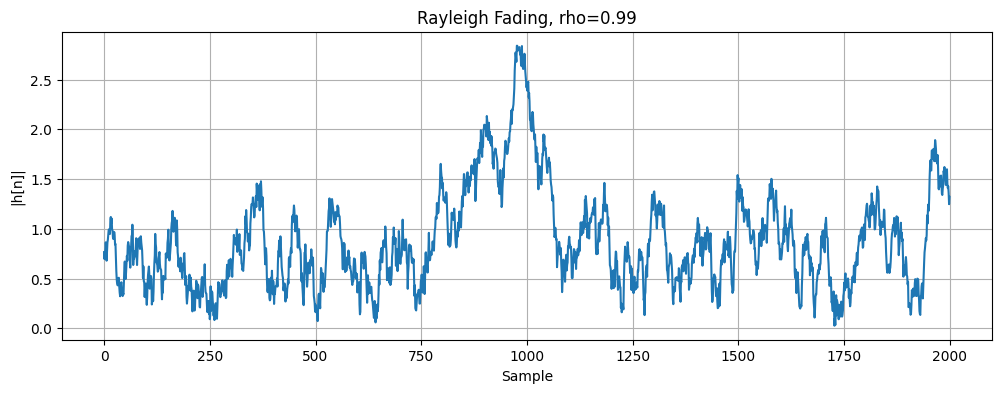

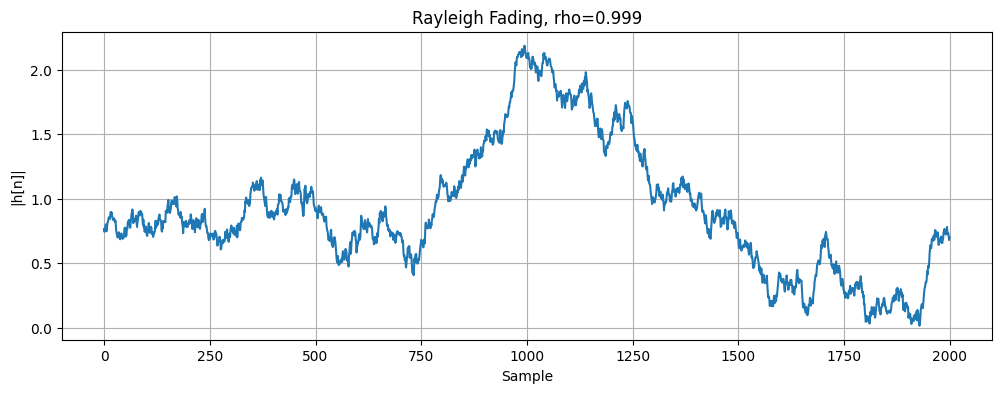

In [166]:
rho_values = [
    0.50,
    0.90,
    0.99,
    0.999
]

for rho in rho_values:

    h_test = generate_correlated_rayleigh_channel(
        num_samples=2000,
        rho=rho,
        rng=np.random.default_rng(42)
    )

    plt.figure(figsize=(12, 4))

    plt.plot(
        np.abs(h_test)
    )

    plt.xlabel("Sample")
    plt.ylabel("|h[n]|")

    plt.title(
        f"Rayleigh Fading, rho={rho}"
    )

    plt.grid()

    plt.show()

In [167]:
from channel.fading import apply_time_varying_fading

In [168]:
faded_waveform = apply_time_varying_fading(
    waveform,
    h
)

print(
    "Signal length:",
    len(waveform)
)

print(
    "Output length:",
    len(faded_waveform)
)

Signal length: 2400
Output length: 2400


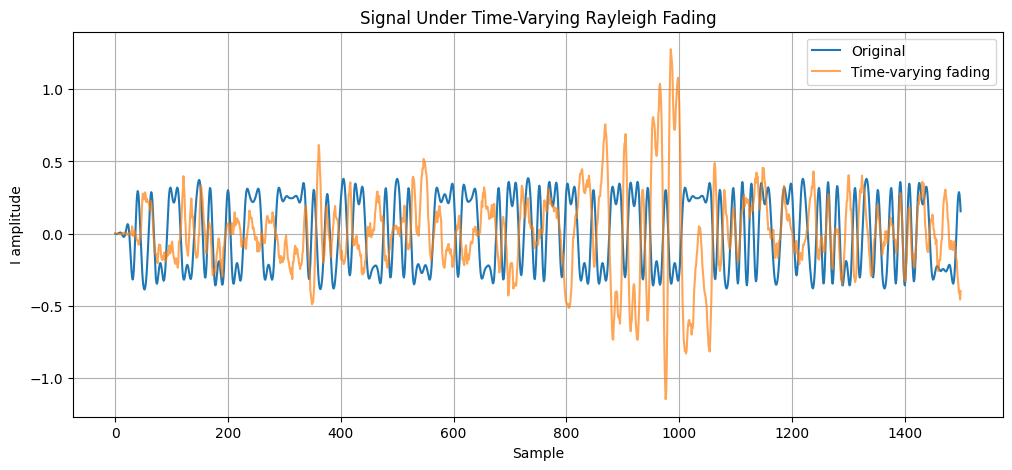

In [169]:
N = min(1500, len(waveform))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(faded_waveform[:N]),
    label="Time-varying fading",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")

plt.title(
    "Signal Under Time-Varying Rayleigh Fading"
)

plt.grid()
plt.legend()

plt.show()

In [170]:
from channel.multipath import apply_time_varying_multipath

In [171]:
rng = np.random.default_rng(123)

num_samples = len(waveform)

h0 = generate_correlated_rayleigh_channel(
    num_samples=num_samples,
    rho=0.995,
    rng=rng
)

h1 = generate_correlated_rayleigh_channel(
    num_samples=num_samples,
    rho=0.995,
    rng=rng
)

In [172]:
h0 *= 1.0
h1 *= 0.5

In [173]:
multipath_faded = apply_time_varying_multipath(
    signal=waveform,
    path_delays=[0, 8],
    path_channels=[
        h0,
        0.5 * h1
    ]
)

print(
    "Input length:",
    len(waveform)
)

print(
    "Output length:",
    len(multipath_faded)
)

Input length: 2400
Output length: 2408


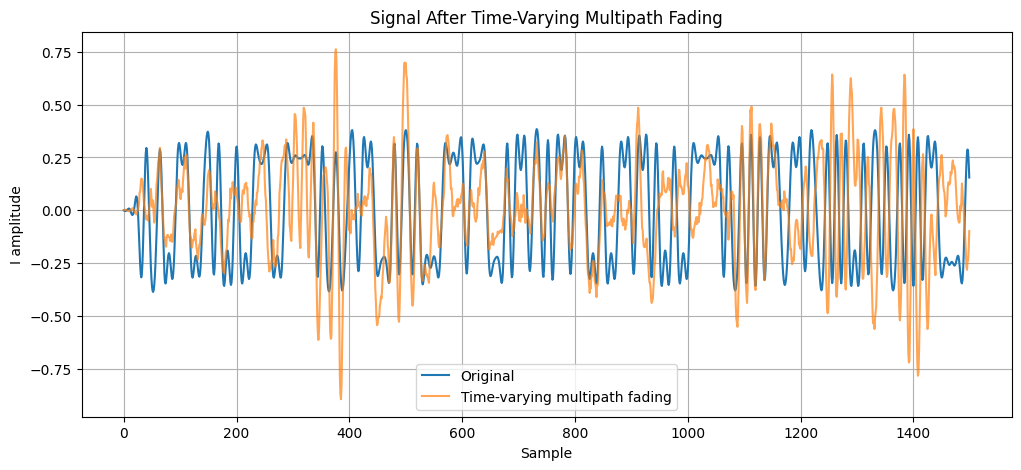

In [174]:
N = min(
    1500,
    len(multipath_faded)
)

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(multipath_faded[:N]),
    label="Time-varying multipath fading",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")

plt.title(
    "Signal After Time-Varying Multipath Fading"
)

plt.grid()
plt.legend()

plt.show()

In [175]:
path0 = waveform * h0

path1 = np.zeros(
    len(waveform) + 8,
    dtype=np.complex128
)

path1[8:] = (
    0.5 * waveform * h1
)

path0_padded = np.zeros_like(path1)

path0_padded[
    :len(waveform)
] = path0

combined = path0_padded + path1

In [176]:
difference = np.max(
    np.abs(
        combined - multipath_faded
    )
)

print(
    "Maximum difference:",
    difference
)

Maximum difference: 0.0


In [177]:
# --------------------------------------------------
# Time-varying fading sanity checks
# --------------------------------------------------

rng = np.random.default_rng(42)

N = len(waveform)

# Generate two independent channels
h0 = generate_correlated_rayleigh_channel(
    N,
    rho=0.99,
    rng=rng
)

h1 = generate_correlated_rayleigh_channel(
    N,
    rho=0.99,
    rng=rng
)

assert len(h0) == N
assert len(h1) == N

assert np.iscomplexobj(h0)
assert np.iscomplexobj(h1)

# Apply time-varying multipath
output = apply_time_varying_multipath(
    waveform,
    path_delays=[0, 8],
    path_channels=[
        h0,
        0.5 * h1
    ]
)

# Correct output length
assert len(output) == N + 8

# No NaN / Inf
assert np.all(
    np.isfinite(output)
)

print(
    "All time-varying multipath fading "
    "tests passed."
)

All time-varying multipath fading tests passed.


In [178]:
from channel.config import ChannelConfig

config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=10,
    cfo_hz=100,
    phase_offset_rad=0.2,
    timing_offset_samples=0.25,
    sro_ppm=20,
    path_delays=[0, 8],
    path_gains=[1.0, 0.5],
    fading_type="rayleigh",
    fading_rho=0.99,
    rician_k=0.0
)

print(config)

ChannelConfig(sample_rate_hz=8000000.0, snr_db=10, cfo_hz=100, phase_offset_rad=0.2, timing_offset_samples=0.25, sro_ppm=20, path_delays=[0, 8], path_gains=[1.0, 0.5], fading_type='rayleigh', fading_rho=0.99, rician_k=0.0)


In [179]:
from channel.simulator import simulate_channel
from channel.config import ChannelConfig

In [180]:
import importlib
import channel.simulator

importlib.reload(channel.simulator)

simulate_channel = channel.simulator.simulate_channel

In [181]:
rng = np.random.default_rng(42)

config = ChannelConfig(
    sample_rate_hz=8e6,

    snr_db=10,

    cfo_hz=200,

    phase_offset_rad=0.4,

    timing_offset_samples=0.25,

    sro_ppm=20,

    path_delays=[0, 8],

    path_gains=[1.0, 0.5],

    fading_type="rayleigh",

    fading_rho=0.99,

    rician_k=0.0
)

In [182]:
received = simulate_channel(
    waveform,
    config,
    rng=np.random.default_rng(42)
)

print(
    "Input length :",
    len(waveform)
)

print(
    "Output length:",
    len(received)
)

Input length : 2400
Output length: 2408


In [183]:
print("First waveform values:")
print(waveform[:5])

print("\nFirst received values:")
print(received[:5])

First waveform values:
[-0.00051083+0.00051083j -0.00220844+0.00220844j -0.00333055+0.00333055j
 -0.00345458+0.00345458j -0.00239344+0.00239344j]

First received values:
[-0.00359721-0.0536609j   0.05573837+0.09942619j  0.07170792+0.00556265j
  0.01015495+0.02869787j  0.08200895-0.01491521j]


In [184]:
print("waveform shape :", waveform.shape)
print("received shape :", received.shape)

print("waveform ndim  :", waveform.ndim)
print("received ndim  :", received.ndim)

print("waveform dtype :", waveform.dtype)
print("received dtype :", received.dtype)

waveform shape : (2400,)
received shape : (2408,)
waveform ndim  : 1
received ndim  : 1
waveform dtype : complex128
received dtype : complex128


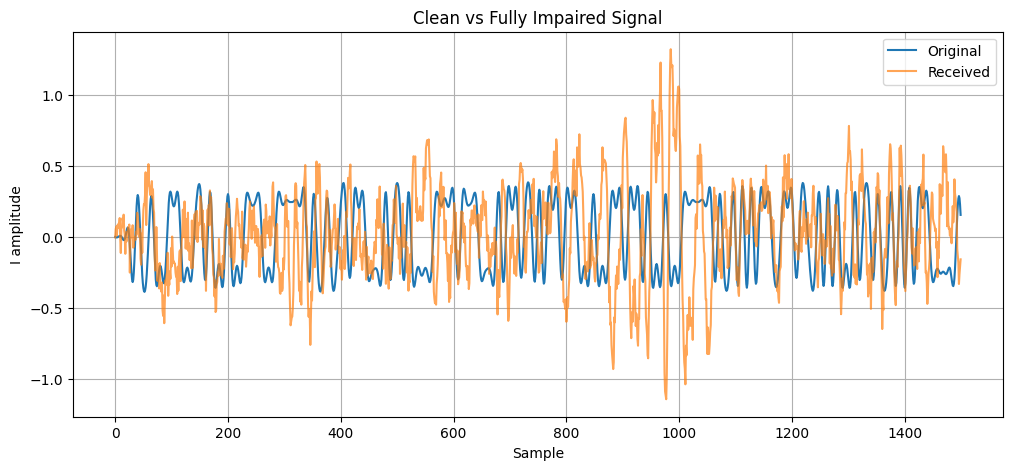

In [185]:
N = min(
    len(waveform),
    len(received),
    1500
)

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(received[:N]),
    label="Received",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")

plt.title(
    "Clean vs Fully Impaired Signal"
)

plt.grid()
plt.legend()

plt.show()

In [186]:
clean_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

clean_output = simulate_channel(
    waveform,
    clean_config,
    rng=np.random.default_rng(42)
)

print("Original shape:", waveform.shape)
print("Output shape  :", clean_output.shape)

print(
    "Maximum error:",
    np.max(np.abs(clean_output - waveform))
)

print(
    "Identical:",
    np.allclose(clean_output, waveform)
)

Original shape: (2400,)
Output shape  : (2400,)
Maximum error: 0.0
Identical: True


In [187]:
signal_power = np.mean(
    np.abs(waveform)**2
)

received_power = np.mean(
    np.abs(received)**2
)

print("Signal power  :", signal_power)
print("Received power:", received_power)

Signal power  : 0.12353166746319488
Received power: 0.1610305921018264


In [188]:
print(
    "Signal RMS:",
    np.sqrt(signal_power)
)

print(
    "Received RMS:",
    np.sqrt(received_power)
)

Signal RMS: 0.351470720634301
Received RMS: 0.4012861723282107


In [189]:
awgn_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=10,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

awgn_output = simulate_channel(
    waveform,
    awgn_config,
    rng=np.random.default_rng(42)
)

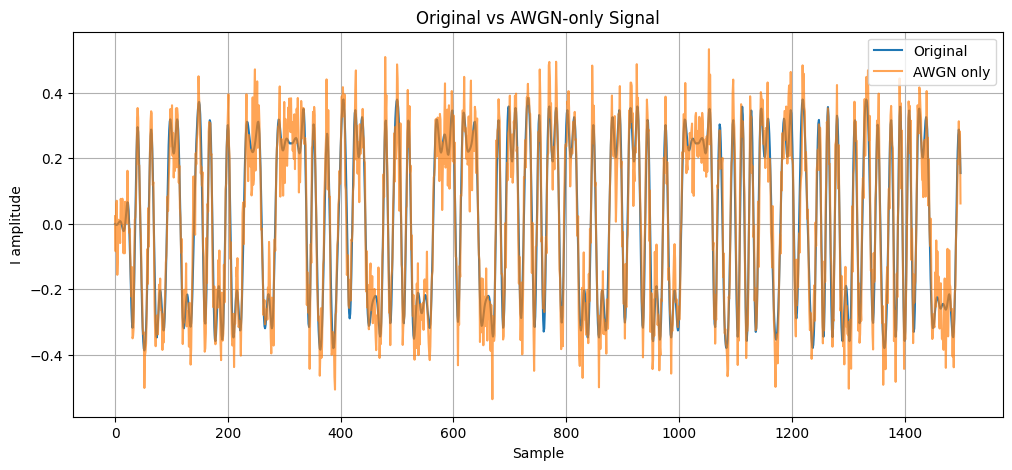

In [190]:
N = min(1500, len(awgn_output))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(awgn_output[:N]),
    label="AWGN only",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")
plt.title("Original vs AWGN-only Signal")
plt.grid()
plt.legend()
plt.show()

In [191]:
fading_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,

    path_delays=[0, 8],
    path_gains=[1.0, 0.5],

    fading_type="rayleigh",
    fading_rho=0.99
)

fading_output = simulate_channel(
    waveform,
    fading_config,
    rng=np.random.default_rng(42)
)

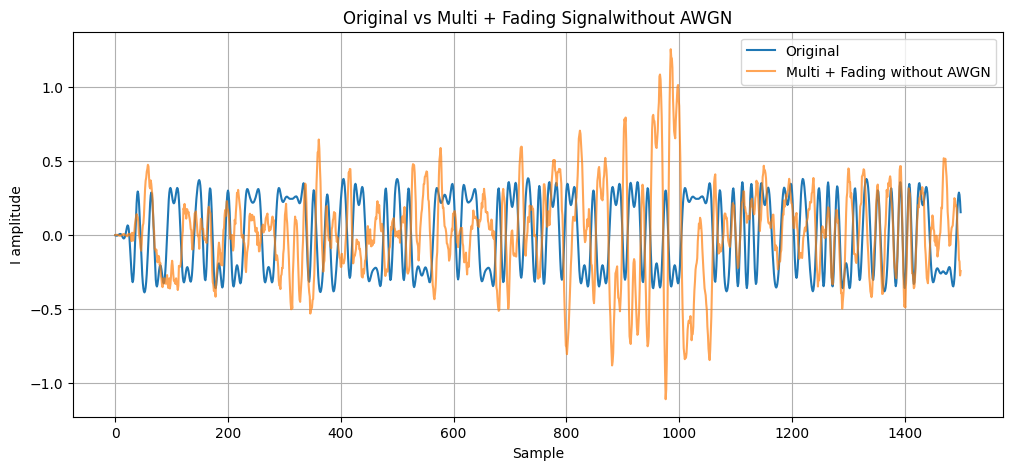

In [192]:
N = min(1500, len(fading_output))

plt.figure(figsize=(12, 5))

plt.plot(
    np.real(waveform[:N]),
    label="Original"
)

plt.plot(
    np.real(fading_output[:N]),
    label="Multi + Fading without AWGN",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")
plt.title("Original vs Multi + Fading Signalwithout AWGN")
plt.grid()
plt.legend()
plt.show()

In [193]:
clean_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

clean_output = simulate_channel(
    waveform,
    clean_config,
    rng=np.random.default_rng(42)
)

print("waveform shape:", waveform.shape)
print("clean_output shape:", clean_output.shape)

print(
    "Maximum error:",
    np.max(np.abs(clean_output - waveform))
)

print(
    "All close:",
    np.allclose(clean_output, waveform)
)

waveform shape: (2400,)
clean_output shape: (2400,)
Maximum error: 0.0
All close: True


In [194]:
print("waveform shape :", waveform.shape)
print("received shape :", received.shape)
print("waveform ndim  :", waveform.ndim)
print("received ndim  :", received.ndim)

waveform shape : (2400,)
received shape : (2408,)
waveform ndim  : 1
received ndim  : 1


In [195]:
awgn_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=10,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

awgn_output = simulate_channel(
    waveform,
    awgn_config,
    rng=np.random.default_rng(42)
)

In [196]:
noise = awgn_output - waveform

signal_power = np.mean(np.abs(waveform) ** 2)
noise_power = np.mean(np.abs(noise) ** 2)

measured_snr_db = 10 * np.log10(
    signal_power / noise_power
)

print("Signal power:", signal_power)
print("Noise power :", noise_power)
print("Measured SNR:", measured_snr_db, "dB")

Signal power: 0.12353166746319488
Noise power : 0.012359427000090172
Measured SNR: 9.997799669468954 dB


In [197]:
fading_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,

    path_delays=[0, 8],
    path_gains=[1.0, 0.5],

    fading_type="rayleigh",
    fading_rho=0.99
)

In [198]:
fading_output = simulate_channel(
    waveform,
    fading_config,
    rng=np.random.default_rng(42)
)

print("Input shape :", waveform.shape)
print("Output shape:", fading_output.shape)

Input shape : (2400,)
Output shape: (2408,)


In [199]:
signal_power = np.mean(
    np.abs(waveform) ** 2
)

fading_power = np.mean(
    np.abs(fading_output) ** 2
)

print("Signal power :", signal_power)
print("Fading output power:", fading_power)

print(
    "Signal RMS:",
    np.sqrt(signal_power)
)

print(
    "Fading output RMS:",
    np.sqrt(fading_power)
)

Signal power : 0.12353166746319488
Fading output power: 0.14660943294409362
Signal RMS: 0.351470720634301
Fading output RMS: 0.38289611246928795


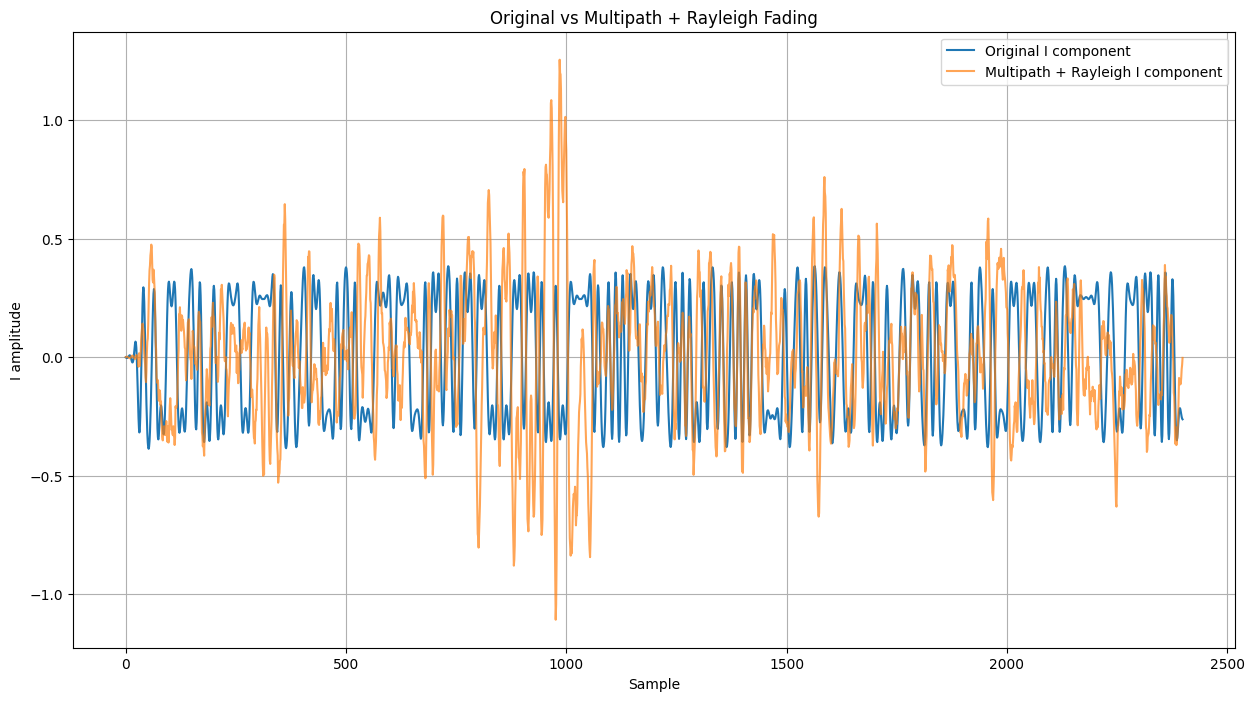

In [200]:
N = min(
    len(waveform),
    len(fading_output)
)

plt.figure(figsize=(15, 8))

plt.plot(
    np.real(waveform[:N]),
    label="Original I component"
)

plt.plot(
    np.real(fading_output[:N]),
    label="Multipath + Rayleigh I component",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")
plt.title("Original vs Multipath + Rayleigh Fading")

plt.grid()
plt.legend()

plt.show()

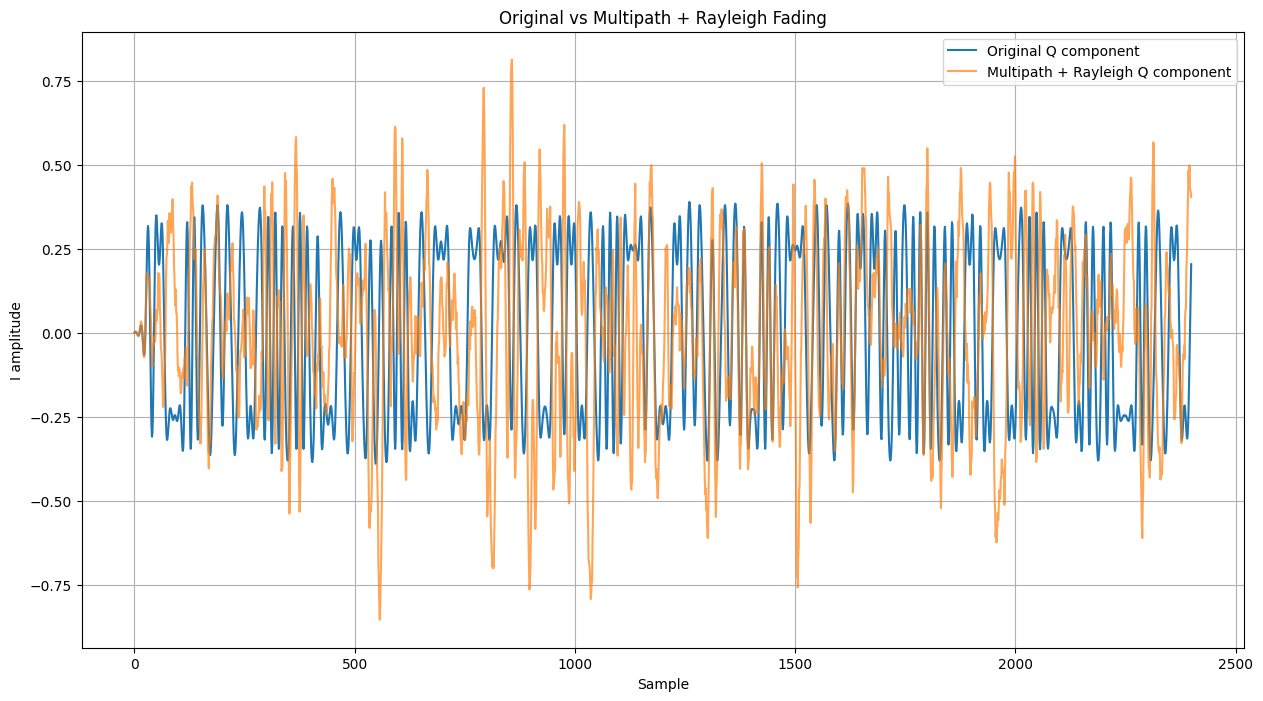

In [201]:
N = min(
    len(waveform),
    len(fading_output)
)

plt.figure(figsize=(15, 8))

plt.plot(
    np.imag(waveform[:N]),
    label="Original Q component"
)

plt.plot(
    np.imag(fading_output[:N]),
    label="Multipath + Rayleigh Q component",
    alpha=0.7
)

plt.xlabel("Sample")
plt.ylabel("I amplitude")
plt.title("Original vs Multipath + Rayleigh Fading")

plt.grid()
plt.legend()

plt.show()

In [202]:
powers = []

for seed in range(100):

    test_output = simulate_channel(
        waveform,
        fading_config,
        rng=np.random.default_rng(seed)
    )

    # Ignore the extra 8 samples caused by the delayed path
    test_output = test_output[:len(waveform)]

    power = np.mean(
        np.abs(test_output) ** 2
    )

    powers.append(power)

powers = np.array(powers)

print("Input power :", signal_power)
print("Mean output power :", np.mean(powers))
print("Std output power  :", np.std(powers))
print("Minimum power    :", np.min(powers))
print("Maximum power    :", np.max(powers))

Input power : 0.12353166746319488
Mean output power : 0.15301531889943368
Std output power  : 0.026783685419114744
Minimum power    : 0.09027648867089741
Maximum power    : 0.24135573186581832


In [203]:
phase_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=np.pi / 2,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

phase_output = simulate_channel(
    waveform,
    phase_config,
    rng=np.random.default_rng(42)
)

In [204]:
expected = waveform * 1j

print(
    "Maximum error:",
    np.max(np.abs(phase_output - expected))
)

print(
    "All close:",
    np.allclose(phase_output, expected)
)

Maximum error: 3.925231146709438e-17
All close: True


In [205]:
cfo_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=1000,
    phase_offset_rad=0,
    timing_offset_samples=0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

cfo_output = simulate_channel(
    waveform,
    cfo_config,
    rng=np.random.default_rng(42)
)

In [206]:
n = np.arange(len(waveform))

expected_cfo = waveform * np.exp(
    1j * 2 * np.pi
    * 1000
    * n
    / 8e6
)

print(
    "Maximum error:",
    np.max(np.abs(cfo_output - expected_cfo))
)

print(
    "All close:",
    np.allclose(cfo_output, expected_cfo)
)

Maximum error: 0.0
All close: True


In [207]:
timing_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0.25,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

timing_output = simulate_channel(
    waveform,
    timing_config,
    rng=np.random.default_rng(42)
)

print("Input shape :", waveform.shape)
print("Output shape:", timing_output.shape)

Input shape : (2400,)
Output shape: (2400,)


In [219]:
timing_zero_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0.0,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

timing_zero_output = simulate_channel(
    waveform,
    timing_zero_config,
    rng=np.random.default_rng(42)
)

print("Input shape:", waveform.shape)
print("Output shape:", timing_zero_output.shape)

print(
    "Maximum error:",
    np.max(np.abs(timing_zero_output - waveform))
)

print(
    "Mean error:",
    np.mean(np.abs(timing_zero_output - waveform))
)

print(
    "Identical:",
    np.allclose(timing_zero_output, waveform)
)

Input shape: (2400,)
Output shape: (2400,)
Maximum error: 0.0
Mean error: 0.0
Identical: True


In [220]:
timing_config = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0,
    phase_offset_rad=0,
    timing_offset_samples=0.25,
    sro_ppm=0,
    path_delays=[0],
    path_gains=[1.0],
    fading_type="none"
)

timing_output = simulate_channel(
    waveform,
    timing_config,
    rng=np.random.default_rng(42)
)

print("Input shape:", waveform.shape)
print("Output shape:", timing_output.shape)

print(
    "Maximum difference:",
    np.max(np.abs(timing_output - waveform))
)

print(
    "Mean absolute difference:",
    np.mean(np.abs(timing_output - waveform))
)

print(
    "Input power:",
    np.mean(np.abs(waveform) ** 2)
)

print(
    "Output power:",
    np.mean(np.abs(timing_output) ** 2)
)

Input shape: (2400,)
Output shape: (2400,)
Maximum difference: 0.044455218022037044
Mean absolute difference: 0.01868595120775432
Input power: 0.12353166746319488
Output power: 0.12217983004494982


In [222]:
import inspect

print(inspect.getsource(simulate_channel))

def simulate_channel(
    signal,
    config,
    rng=None
):

    if rng is None:
        rng = np.random.default_rng()

    received = np.asarray(
        signal,
        dtype=np.complex128
    ).copy()

    # 1. Multipath + fading
    received = _apply_channel_fading(
        received,
        config,
        rng
    )

    # 2. Phase offset
    if config.phase_offset_rad != 0:

        received = apply_phase_offset(
            received,
            config.phase_offset_rad
        )

    # 3. CFO
    if config.cfo_hz != 0:

        received = apply_cfo(
            received,
            cfo_hz=config.cfo_hz,
            sample_rate_hz=config.sample_rate_hz
        )

    # 4. Fractional timing offset
    if config.timing_offset_samples != 0:

        received = apply_fractional_timing_offset(
            received,
            config.timing_offset_samples
        )

    # 5. SRO
    if config.sro_ppm != 0:

        received = apply_sample_rate_offset(
            received,
        

In [223]:
fs = 1e6
f = 50e3
tau = 0.25

n = np.arange(1000)

test_signal = np.exp(
    1j * 2 * np.pi * f * n / fs
)

# Apply your timing function directly
fractional_output = apply_fractional_timing_offset(
    test_signal,
    tau
)

print("Input shape:", test_signal.shape)
print("Output shape:", fractional_output.shape)

print(
    "Input power:",
    np.mean(np.abs(test_signal) ** 2)
)

print(
    "Output power:",
    np.mean(np.abs(fractional_output) ** 2)
)

Input shape: (1000,)
Output shape: (1000,)
Input power: 1.0
Output power: 0.9806645474170721


In [224]:
margin = 20

input_power_interior = np.mean(
    np.abs(test_signal[margin:-margin]) ** 2
)

output_power_interior = np.mean(
    np.abs(fractional_output[margin:-margin]) ** 2
)

print(
    "Input interior power:",
    input_power_interior
)

print(
    "Output interior power:",
    output_power_interior
)

print(
    "Relative power change (%):",
    (
        (output_power_interior - input_power_interior)
        / input_power_interior
    ) * 100
)

Input interior power: 1.0
Output interior power: 0.9816461936106826
Relative power change (%): -1.8353806389317384


In [225]:
expected_phase_shift = (
    -2 * np.pi * f * tau / fs
)

print(
    "Expected phase shift (rad):",
    expected_phase_shift
)

# Compare the interior samples
margin = 20

ratio = (
    fractional_output[margin:-margin]
    / test_signal[margin:-margin]
)

measured_phase = np.angle(ratio)

# Because phase is wrapped to [-pi, pi],
# use the circular mean
measured_phase_shift = np.angle(
    np.mean(np.exp(1j * measured_phase))
)

print(
    "Measured phase shift (rad):",
    measured_phase_shift
)

print(
    "Phase error (rad):",
    measured_phase_shift - expected_phase_shift
)

Expected phase shift (rad): -0.07853981633974483
Measured phase shift (rad): -0.0780523412600425
Phase error (rad): 0.00048747507970232917


In [226]:
fs = 1e6
f = 50e3

n = np.arange(1000)

test_signal = np.exp(
    1j * 2 * np.pi * f * n / fs
)

delays = [0.10, 0.25, 0.50, 0.75, 0.90]

margin = 20

input_power = np.mean(
    np.abs(test_signal[margin:-margin]) ** 2
)

print("Input interior power:", input_power)
print()

for tau in delays:

    output = apply_fractional_timing_offset(
        test_signal,
        tau
    )

    output_power = np.mean(
        np.abs(output[margin:-margin]) ** 2
    )

    relative_change = (
        (output_power - input_power)
        / input_power
    ) * 100

    expected_phase = (
        -2 * np.pi * f * tau / fs
    )

    ratio = (
        output[margin:-margin]
        / test_signal[margin:-margin]
    )

    measured_phase = np.angle(
        np.mean(ratio)
    )

    phase_error = (
        measured_phase - expected_phase
    )

    print(f"tau = {tau:.2f} samples")
    print(f"  Output power:       {output_power:.9f}")
    print(f"  Power change (%):   {relative_change:.6f}")
    print(f"  Expected phase:     {expected_phase:.9f} rad")
    print(f"  Measured phase:     {measured_phase:.9f} rad")
    print(f"  Phase error:        {phase_error:.9f} rad")
    print()

Input interior power: 1.0

tau = 0.10 samples
  Output power:       0.991190173
  Power change (%):   -0.880983
  Expected phase:     -0.031415927 rad
  Measured phase:     -0.031043711 rad
  Phase error:        0.000372216 rad

tau = 0.25 samples
  Output power:       0.981646194
  Power change (%):   -1.835381
  Expected phase:     -0.078539816 rad
  Measured phase:     -0.078052341 rad
  Phase error:        0.000487475 rad

tau = 0.50 samples
  Output power:       0.975528258
  Power change (%):   -2.447174
  Expected phase:     -0.157079633 rad
  Measured phase:     -0.157079633 rad
  Phase error:        0.000000000 rad

tau = 0.75 samples
  Output power:       0.981646194
  Power change (%):   -1.835381
  Expected phase:     -0.235619449 rad
  Measured phase:     -0.236106924 rad
  Phase error:        -0.000487475 rad

tau = 0.90 samples
  Output power:       0.991190173
  Power change (%):   -0.880983
  Expected phase:     -0.282743339 rad
  Measured phase:     -0.283115555 rad
 

In [227]:
delays = [0.10, 0.25, 0.50, 0.75, 0.90]

input_power = np.mean(
    np.abs(waveform) ** 2
)

input_rms = np.sqrt(input_power)

print("Original waveform shape:", waveform.shape)
print("Original power:", input_power)
print("Original RMS:", input_rms)
print()

for tau in delays:

    output = apply_fractional_timing_offset(
        waveform,
        tau
    )

    output_power = np.mean(
        np.abs(output) ** 2
    )

    output_rms = np.sqrt(output_power)

    power_change = (
        (output_power - input_power)
        / input_power
    ) * 100

    max_difference = np.max(
        np.abs(output - waveform)
    )

    mean_difference = np.mean(
        np.abs(output - waveform)
    )

    print(f"tau = {tau:.2f} samples")
    print(f"  Output shape:       {output.shape}")
    print(f"  Output power:       {output_power:.9f}")
    print(f"  Output RMS:         {output_rms:.9f}")
    print(f"  Power change (%):   {power_change:.6f}")
    print(f"  Maximum difference: {max_difference:.9f}")
    print(f"  Mean difference:    {mean_difference:.9f}")
    print()

Original waveform shape: (2400,)
Original power: 0.12353166746319488
Original RMS: 0.351470720634301

tau = 0.10 samples
  Output shape:       (2400,)
  Output power:       0.122883705
  Output RMS:         0.350547722
  Power change (%):   -0.524531
  Maximum difference: 0.017782087
  Mean difference:    0.007474561

tau = 0.25 samples
  Output shape:       (2400,)
  Output power:       0.122179830
  Output RMS:         0.349542315
  Power change (%):   -1.094325
  Maximum difference: 0.044455218
  Mean difference:    0.018685951

tau = 0.50 samples
  Output shape:       (2400,)
  Output power:       0.121721550
  Output RMS:         0.348886156
  Power change (%):   -1.465306
  Maximum difference: 0.088910436
  Mean difference:    0.037371601

tau = 0.75 samples
  Output shape:       (2400,)
  Output power:       0.122156827
  Output RMS:         0.349509410
  Power change (%):   -1.112945
  Maximum difference: 0.133365654
  Mean difference:    0.056057252

tau = 0.90 samples
  Outpu

In [228]:
tau = 0.5

timed_output = apply_fractional_timing_offset(
    waveform,
    tau
)

print("Input shape:", waveform.shape)
print("Output shape:", timed_output.shape)

# Compare correlation between original and delayed waveform
correlation = np.vdot(
    waveform,
    timed_output
)

normalized_correlation = (
    np.abs(correlation)
    / (
        np.linalg.norm(waveform)
        * np.linalg.norm(timed_output)
    )
)

print("Normalized correlation:", normalized_correlation)

# Difference
difference = timed_output - waveform

print("Maximum difference:", np.max(np.abs(difference)))
print("Mean absolute difference:", np.mean(np.abs(difference)))

# Power
input_power = np.mean(np.abs(waveform) ** 2)
output_power = np.mean(np.abs(timed_output) ** 2)

print("Input power:", input_power)
print("Output power:", output_power)

print(
    "Power change (%):",
    ((output_power - input_power) / input_power) * 100
)

Input shape: (2400,)
Output shape: (2400,)
Normalized correlation: 0.9927488113617141
Maximum difference: 0.08891043604407409
Mean absolute difference: 0.03737160140780359
Input power: 0.12353166746319488
Output power: 0.12172155009226637
Power change (%): -1.4653063526952048


In [230]:
fs = 8e6
sro_ppm = 0.0

output = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=fs,
    sro_ppm=sro_ppm
)

print("Input shape:", waveform.shape)
print("Output shape:", output.shape)

difference = output - waveform

print("Maximum error:", np.max(np.abs(difference)))
print("Mean absolute error:", np.mean(np.abs(difference)))
print("Identical:", np.allclose(output, waveform))

input_power = np.mean(np.abs(waveform) ** 2)
output_power = np.mean(np.abs(output) ** 2)

print("Input power:", input_power)
print("Output power:", output_power)

Input shape: (2400,)
Output shape: (2400,)
Maximum error: 3.611706891580313e-14
Mean absolute error: 3.648296349072744e-16
Identical: True
Input power: 0.12353166746319488
Output power: 0.12353166746319481


In [231]:
fs = 8e6
sro_ppm = 100.0

output = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=fs,
    sro_ppm=sro_ppm
)

print("Input shape:", waveform.shape)
print("Output shape:", output.shape)

difference = output - waveform

print("Maximum difference:", np.max(np.abs(difference)))
print("Mean absolute difference:", np.mean(np.abs(difference)))

input_power = np.mean(np.abs(waveform) ** 2)
output_power = np.mean(np.abs(output) ** 2)

print("Input power:", input_power)
print("Output power:", output_power)

print(
    "Power change (%):",
    ((output_power - input_power) / input_power) * 100
)

print(
    "Identical:",
    np.allclose(output, waveform)
)

Input shape: (2400,)
Output shape: (2400,)
Maximum difference: 0.036886777578793634
Mean absolute difference: 0.009177363576886947
Input power: 0.12353166746319488
Output power: 0.12278919515089384
Power change (%): -0.6010380395150522
Identical: False


In [233]:
fs = 8e6
sro_ppm = -100.0

output = apply_sample_rate_offset(
    waveform,
    sample_rate_hz=fs,
    sro_ppm=sro_ppm
)

print("Input shape:", waveform.shape)
print("Output shape:", output.shape)

input_power = np.mean(np.abs(waveform) ** 2)
output_power = np.mean(np.abs(output) ** 2)

print("Input power:", input_power)
print("Output power:", output_power)

print(
    "Power change (%):",
    ((output_power - input_power) / input_power) * 100
)

print("Output length difference:", len(output) - len(waveform))

Input shape: (2400,)
Output shape: (2399,)
Input power: 0.12353166746319488
Output power: 0.12279214214798938
Power change (%): -0.5986524187620474
Output length difference: -1


In [234]:
fs = 8e6
sro_ppm = -100.0
N = len(waveform)

epsilon = sro_ppm / 1e6

fs_actual = fs * (1 + epsilon)

resampling_ratio = fs_actual / fs

expected_samples = N * resampling_ratio

print("Nominal sample rate:", fs)
print("SRO (ppm):", sro_ppm)
print("Fractional SRO:", epsilon)
print("Actual sample rate:", fs_actual)
print("Resampling ratio:", resampling_ratio)
print("Input samples:", N)
print("Theoretical output samples:", expected_samples)

print()
print("Actual output samples:", len(output))
print("Difference from theoretical:", len(output) - expected_samples)

Nominal sample rate: 8000000.0
SRO (ppm): -100.0
Fractional SRO: -0.0001
Actual sample rate: 7999200.0
Resampling ratio: 0.9999
Input samples: 2400
Theoretical output samples: 2399.76

Actual output samples: 2399
Difference from theoretical: -0.7600000000002183


In [235]:
sro_values = [
    -100,
    -50,
    0,
    50,
    100
]

print("Input length:", len(waveform))
print()

for sro_ppm in sro_values:

    output = apply_sample_rate_offset(
        waveform,
        sample_rate_hz=8e6,
        sro_ppm=sro_ppm
    )

    # Compare only overlapping samples
    N = min(
        len(waveform),
        len(output)
    )

    difference = output[:N] - waveform[:N]

    mean_difference = np.mean(
        np.abs(difference)
    )

    max_difference = np.max(
        np.abs(difference)
    )

    print(f"SRO = {sro_ppm:+d} ppm")
    print(f"  Output length:       {len(output)}")
    print(f"  Mean difference:     {mean_difference:.9f}")
    print(f"  Maximum difference:  {max_difference:.9f}")
    print()

Input length: 2400

SRO = -100 ppm
  Output length:       2399
  Mean difference:     0.009175547
  Maximum difference:  0.036878449

SRO = -50 ppm
  Output length:       2399
  Mean difference:     0.004587544
  Maximum difference:  0.018438303

SRO = +0 ppm
  Output length:       2400
  Mean difference:     0.000000000
  Maximum difference:  0.000000000

SRO = +50 ppm
  Output length:       2400
  Mean difference:     0.004588911
  Maximum difference:  0.018444311

SRO = +100 ppm
  Output length:       2400
  Mean difference:     0.009177364
  Maximum difference:  0.036886778



In [236]:
config_multipath = ChannelConfig(
    sample_rate_hz=8e6,
    snr_db=None,
    cfo_hz=0.0,
    phase_offset_rad=0.0,
    timing_offset_samples=0.0,
    sro_ppm=0.0,
    path_delays=[0, 8],
    path_gains=[1.0, 0.5],
    fading_type="none"
)

output = simulate_channel(
    waveform,
    config_multipath,
    rng=np.random.default_rng(42)
)

input_power = np.mean(
    np.abs(waveform) ** 2
)

output_power = np.mean(
    np.abs(output) ** 2
)

print("Input shape:", waveform.shape)
print("Output shape:", output.shape)

print("Input power:", input_power)
print("Output power:", output_power)

print(
    "Power change (%):",
    ((output_power - input_power) / input_power) * 100
)

print(
    "Input RMS:",
    np.sqrt(input_power)
)

print(
    "Output RMS:",
    np.sqrt(output_power)
)

Input shape: (2400,)
Output shape: (2408,)
Input power: 0.12353166746319488
Output power: 0.14881351296385073
Power change (%): 20.4658821659542
Input RMS: 0.351470720634301
Output RMS: 0.3857635454055382


In [237]:
gain_configs = [
    [1.0, 0.0],
    [1.0, 0.5],
    [1.0, 1.0]
]

for gains in gain_configs:

    config_test = ChannelConfig(
        sample_rate_hz=8e6,
        snr_db=None,
        cfo_hz=0.0,
        phase_offset_rad=0.0,
        timing_offset_samples=0.0,
        sro_ppm=0.0,
        path_delays=[0, 8],
        path_gains=gains,
        fading_type="none"
    )

    output = simulate_channel(
        waveform,
        config_test,
        rng=np.random.default_rng(42)
    )

    input_power = np.mean(
        np.abs(waveform) ** 2
    )

    output_power = np.mean(
        np.abs(output) ** 2
    )

    print(f"Path gains: {gains}")
    print(f"  Output shape:     {output.shape}")
    print(f"  Output power:     {output_power:.9f}")
    print(
        f"  Power change:     "
        f"{((output_power - input_power) / input_power) * 100:.6f}%"
    )
    print()

Path gains: [1.0, 0.0]
  Output shape:     (2408,)
  Output power:     0.123121263
  Power change:     -0.332226%

Path gains: [1.0, 0.5]
  Output shape:     (2408,)
  Output power:     0.148813513
  Power change:     20.465882%

Path gains: [1.0, 1.0]
  Output shape:     (2408,)
  Output power:     0.236066394
  Power change:     91.097877%

